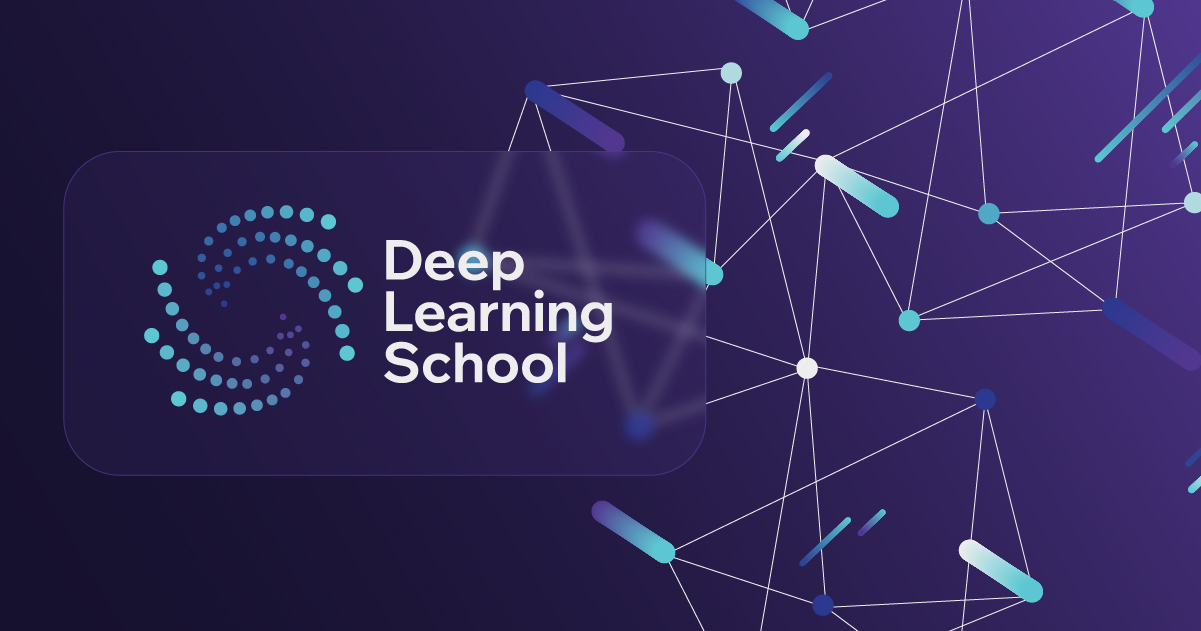

# Attn in SDXL

Notebook author: **Nina Konovalova**

**mail**: nina.konovalova.k@gmail.com

**tg**: @AfeliaN

**tg-channel**: [t.me/reading_ai](https://t.me/reading_ai)

We will work with SDXL, a U-Net diffusion model that generates images from text.

The notebook has two parts:

* **Observe**. We record attention. Where does each word appear? When does the model mix up words? When and in which block does it decide the layout? What does self-attention tell us about shapes?
* **Intervene**. We will try to manipulate our image generation by intervantion in attn layers.

> **GPU.** A free Colab **T4 (16 GB)** is enough.

## Setup and tools

We first set up our tools.

### Setup

First, install and import the libraries.

In [2]:
!pip -q install "diffusers>=0.30" transformers accelerate scikit-learn

In [4]:
import math
from difflib import SequenceMatcher

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import StableDiffusionXLPipeline, AutoencoderKL, AutoencoderTiny

DEVICE = "cuda"
DTYPE = torch.float16
MODEL_ID = "stabilityai/stable-diffusion-xl-base-1.0"
VAE_ID = "madebyollin/sdxl-vae-fp16-fix"   # the original SDXL VAE overflows in fp16
TAESD_ID = "madebyollin/taesdxl"           # tiny decoder for cheap previews of the predicted x0
RES = 1024                                 # 768 is ~2x faster and still fine for SDXL
STEPS = 30
GUIDANCE = 7.0
SEED = 0
torch.set_grad_enabled(False)

torch.autograd.grad_mode.set_grad_enabled(mode=False)

We load SDXL with a corrected SDXL VAE, since the original overflows in fp16.

In [6]:
pipe = StableDiffusionXLPipeline.from_pretrained(
    MODEL_ID, torch_dtype=DTYPE, variant="fp16", use_safetensors=True,   # fp16 files: half the download, fits Colab RAM
    vae=AutoencoderKL.from_pretrained(VAE_ID, torch_dtype=DTYPE),
).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
taesd = AutoencoderTiny.from_pretrained(TAESD_ID, torch_dtype=DTYPE).to(DEVICE)
# Tokenizer is used to tokenize the prompt.
tok = pipe.tokenizer

CTX_LEN = tok.model_max_length   # 77 text positions
# Check if the GPU is available and print the memory allocated after loading.
if torch.cuda.is_available():
    print(f"GPU memory after loading: {torch.cuda.memory_allocated() / 2**30:.1f} GB")

GPU memory after loading: 6.6 GB


### Seeing and changing attention

In this notebook we look inside the attention layers of SDXL. Every transformer block of the U-Net is a stack of layers, and each transformer's block has two attention modules: **self-attention** `attn1`, where image patches look at each other, and
**cross-attention** `attn2`, where image patches look at the words of the prompt.

This section builds the tools to work with these attn maps: an attention processor that computes the map explicitly, `generate` with hooks, and word heatmaps.

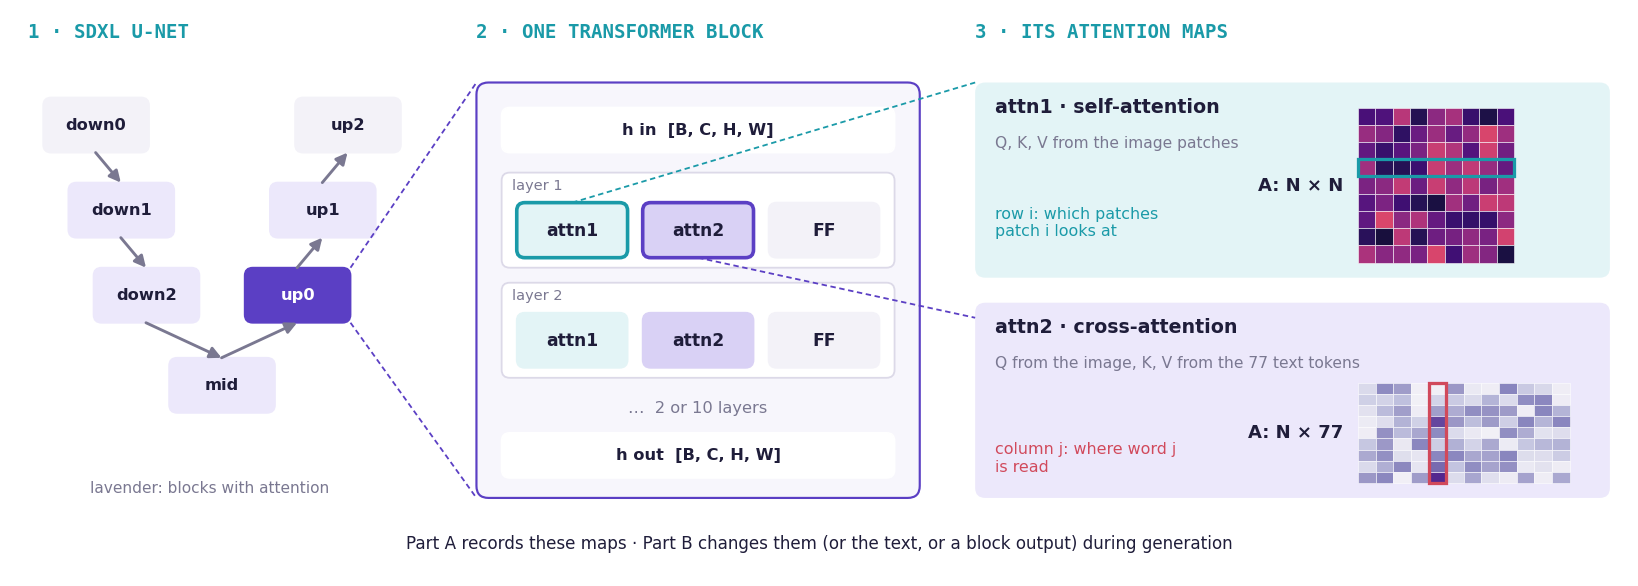

Each attention layer mixes information through an attention map $A$:

$$A = \mathrm{softmax}\!\Big(\frac{QK^\top}{\sqrt d}\Big), \qquad \text{out} = AV.$$

Queries $Q$ come from $N$ image patches. Here $d$ is the query/key dimension. Keys $K$ and values $V$ come from:

| layer | keys / values from | map $A$ | row $i$ shows |
|---|---|---|---|
| **cross-attention** (`attn2`) | the 77 text tokens | $N \times 77$ | which words patch $i$ attends to |
| **self-attention** (`attn1`) | the image patches | $N \times N$ | which patches patch $i$ attends to |

So **column $j$ of a cross-attention map is a heatmap of where word $j$ is drawn.**

**Why the formula looks like this.** Read it from the inside out.

- **$QK^\top$: how well each query matches each key.** Entry $(i, j)$ is the dot product $q_i \cdot k_j$. It is large
  when the two vectors point in the same direction, so it is a similarity score. One matrix product gives the scores for
  all pairs at once.
- **$/\sqrt d$: keep the scores in a sane range.** A dot product sums $d$ terms. If the components are random with
  variance 1, the sum has variance $d$, so the scores grow like $\sqrt d$ (in SDXL $d = 64$ per head). Large scores make
  the softmax almost one-hot: one key takes all the weight, and the gradients vanish. Dividing by $\sqrt d$ brings the
  scores back to variance 1 for any $d$.
- **softmax over each row: turn scores into a probability distribution.** With the scaled scores $s_{ij} = q_i \cdot k_j / \sqrt d$, the weights $A_{ij} = e^{s_{ij}} / \sum_{j'} e^{s_{ij'}}$
  is positive, and every row sums to 1. So row $i$ says how patch $i$ splits its attention between the keys.
- **$AV$: a weighted average.** The output of patch $i$ is $\sum_j A_{ij} v_j$, a mix of the values, where the keys
  that match best contribute the most.

In [8]:
def block_of(layer_name):
    """Block a layer belongs to: 'up_blocks.1.attentions.2.transformer_blocks.0.attn2' -> 'up_blocks.1.attentions.2'."""
    return layer_name.split(".transformer_blocks")[0]


MODULES = dict(pipe.unet.named_modules())   # name -> module, for every module of the U-Net
N_LAYERS = {name: len(m.transformer_blocks) for name, m in MODULES.items()   # block -> number of transformer layers
            if type(m).__name__ == "Transformer2DModel"}

# Settings of the running generation: `generate` writes them, the attention layers read them.
RUN = dict(step=0, cfg=True, edits=[], self_blocks=set(), text_hooks={}, block_hooks={})
CROSS = {}   # (block, step) -> [N, 77] cross-attention map of the last generation, mean over heads and layers


class AttnProcessor:
    """Attention of one layer, written out step by step so that we can see and change the map A.

    A = softmax(Q K^T / sqrt(d)) is built for every cross-attention layer, and for self-attention only in the blocks
    in RUN["self_blocks"] (a 64×64 self-attention map has 4096 x 4096 entries per head). Every function in RUN["edits"]
    gets A and may return a changed copy. Then out = A V. All other layers use the fast fused kernel.
    """

    def __init__(self, layer_name):
        self.block = block_of(layer_name)

    def __call__(self, attn, hidden_states, encoder_hidden_states=None, attention_mask=None, **kwargs):
        assert attention_mask is None, "written for the SDXL U-Net"
        cross = encoder_hidden_states is not None                          # attn2 gets the text, attn1 does not
        if cross and self.block in RUN["text_hooks"]:                      # used in §6: read another text
            encoder_hidden_states = RUN["text_hooks"][self.block](encoder_hidden_states, RUN["step"])
        source = encoder_hidden_states if cross else hidden_states         # keys and values come from here
        B, N, _ = hidden_states.shape
        H = attn.heads
        q, k, v = attn.to_q(hidden_states), attn.to_k(source), attn.to_v(source)
        q, k, v = (x.view(B, -1, H, x.shape[-1] // H).transpose(1, 2) for x in (q, k, v))   # split heads: [B, H, tokens, d]

        if cross or self.block in RUN["self_blocks"]:
            A = (q @ k.transpose(-1, -2) * attn.scale).float().softmax(-1)    # [B, H, N, keys]; float32, fp16 underflows
            info = dict(block=self.block, step=RUN["step"], cross=cross,
                        cond=slice(B // 2, B) if RUN["cfg"] else slice(0, B))   # CFG batch = [uncond, cond]: prompt rows
            for edit in RUN["edits"]:                                       # let every edit see (and change) A
                A = edit(A, info)
            out = A.to(v.dtype) @ v
        else:
            out = F.scaled_dot_product_attention(q, k, v)                    # same result, A is never stored

        out = out.transpose(1, 2).reshape(B, N, -1)                          # concatenate the heads
        return attn.to_out[1](attn.to_out[0](out))                           # output projection (+ dropout)


def record_cross(A, info):
    """Edit that changes nothing: adds the prompt-branch cross-attention map, averaged over heads, to CROSS."""
    if info["cross"]:
        key = (info["block"], info["step"])
        m = A[info["cond"]].mean(dim=(0, 1)).cpu() / N_LAYERS[info["block"]]   # mean over images, heads, layers
        CROSS[key] = CROSS.get(key, 0) + m                                      # sum over the layers of the block
    return A


pipe.unet.set_attn_processor({name: AttnProcessor(name) for name in pipe.unet.attn_processors})   # install everywhere

`generate` runs the pipeline. Pass changes as arguments, with no manual reset:

* `edits=[...]`: edits to $A$ wherever it is computed, including all cross-attention layers.
* `self_blocks=[...]`: blocks where we also compute self-attention maps $A$ for the edits.
* `block_hooks={block: f}`: `f(h, step)` receives block output $h$, shape $[B, C, H, W]$ (batch, channels, height,
  width), and may replace it.
* `text_hooks={block: f}`: `f(c, step)` returns text embeddings $c$ for a block’s cross-attention.

Each call of `generate` overwrites these settings in `RUN`, so interrupted runs leave no settings behind.

Where each argument acts inside one transformer block:

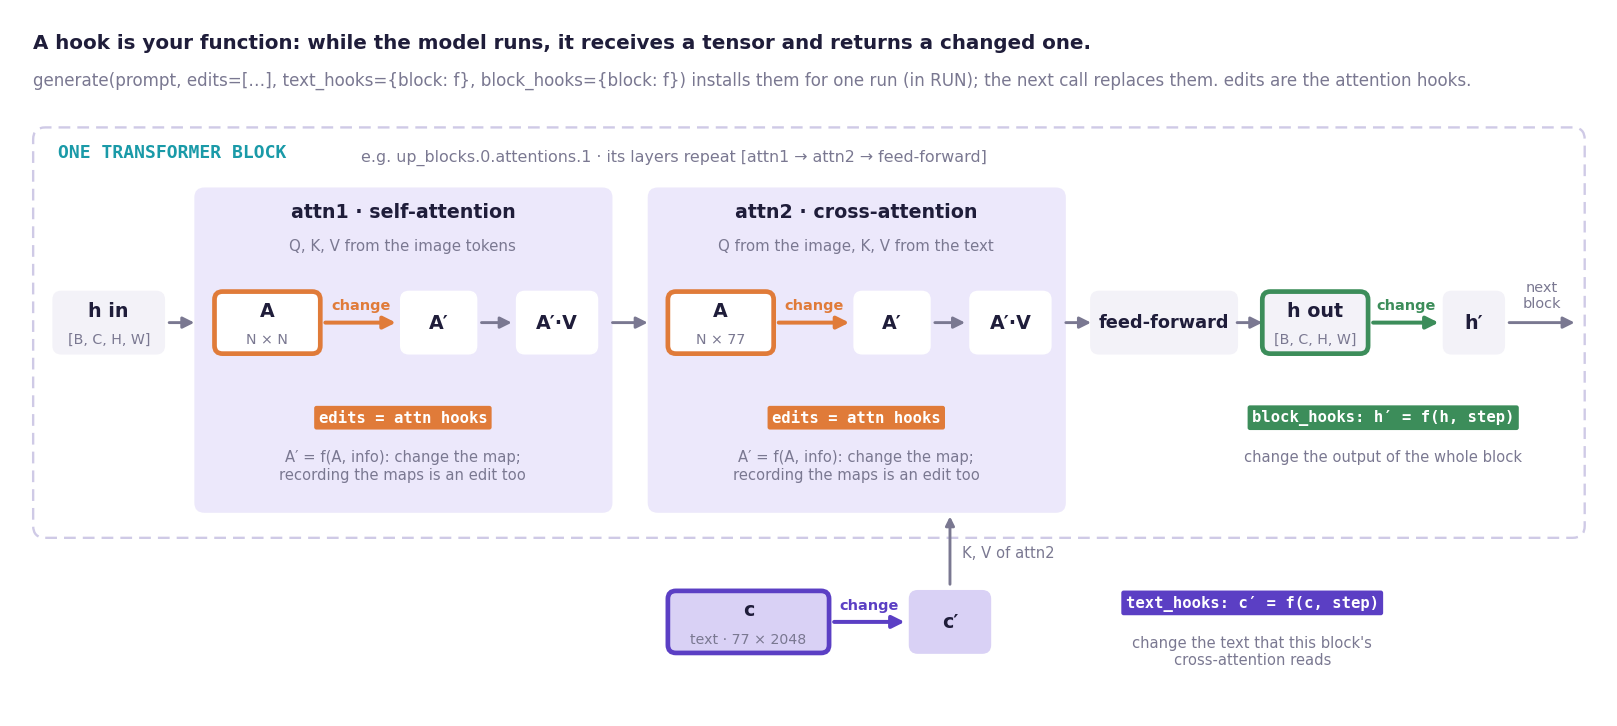

In [10]:
def forward_with_hook(block):
    """New forward of a block: the original forward, then RUN["block_hooks"][block](h, step) if this run has one."""
    module, forward = MODULES[block], type(MODULES[block]).forward     # the class method = the original forward

    def new_forward(*args, **kwargs):
        out = forward(module, *args, **kwargs)                          # a tuple; out[0] is the block output h
        f = RUN["block_hooks"].get(block)
        new = f(out[0], RUN["step"]) if f else None                     # the hook may return a new h
        return out if new is None else (new, *out[1:])

    return new_forward


for b in N_LAYERS:
    MODULES[b].forward = forward_with_hook(b)


def generate(prompt, seed=SEED, steps=STEPS, guidance=GUIDANCE, edits=(), self_blocks=(), block_hooks=None,
             text_hooks=None, record=True, **pipe_kwargs):
    """Generate an image with SDXL; the cross-attention maps of this run end up in CROSS.

    Args:
        prompt: a string, or a list of strings for a batch (used by Prompt-to-Prompt)
        edits: functions edit(A, info) -> A; info is a dict with "block", "step", "cross" (True = cross-attention) and "cond"
        self_blocks: blocks where self-attention A is built and passed to the edits
        block_hooks: {block: f(h, step)}; f returns a new block output, or None to keep h
        text_hooks: {block: f(c, step)}; f returns the text embeddings that the block's cross-attention reads
        record: record cross-attention into CROSS
        pipe_kwargs: passed to the pipeline (latents=, prompt_embeds=, ...)
    Returns: a PIL image (a list of images for a list of prompts)
    """
    CROSS.clear()
    RUN.update(step=0, cfg=guidance > 1, edits=list(edits) + ([record_cross] if record else []),   # settings of this run
               self_blocks=set(self_blocks), block_hooks=block_hooks or {}, text_hooks=text_hooks or {})

    def count_step(pipe_, i, t, kw):                                    # the pipeline calls it after every step
        RUN["step"] = i + 1
        return kw

    images = pipe(prompt, num_inference_steps=steps, guidance_scale=guidance, height=RES, width=RES,
                  generator=torch.Generator("cpu").manual_seed(seed), callback_on_step_end=count_step,
                  **pipe_kwargs).images
    return images if isinstance(prompt, list) else images[0]

### Word heatmaps

For word $w$, $J_w$ lists its token positions. We upsample their columns to one grid and sum over blocks $\ell$ and
steps $t$:

$$D_w = \sum_{\ell,\,t}\ \sum_{j \in J_w} \mathrm{Up}\big(\bar A^{(\ell,t)}_{:,j}\big), \qquad
\tilde D_w = \frac{D_w - \min D_w}{\max D_w - \min D_w}, \qquad M_w = [\tilde D_w > \tau],\ \tau = 0.4,$$

Here $\bar A$ averages heads and layers, $\mathrm{Up}$ upsamples, and $M_w$ thresholds the normalized map $\tilde D_w$.

The same steps as a picture:

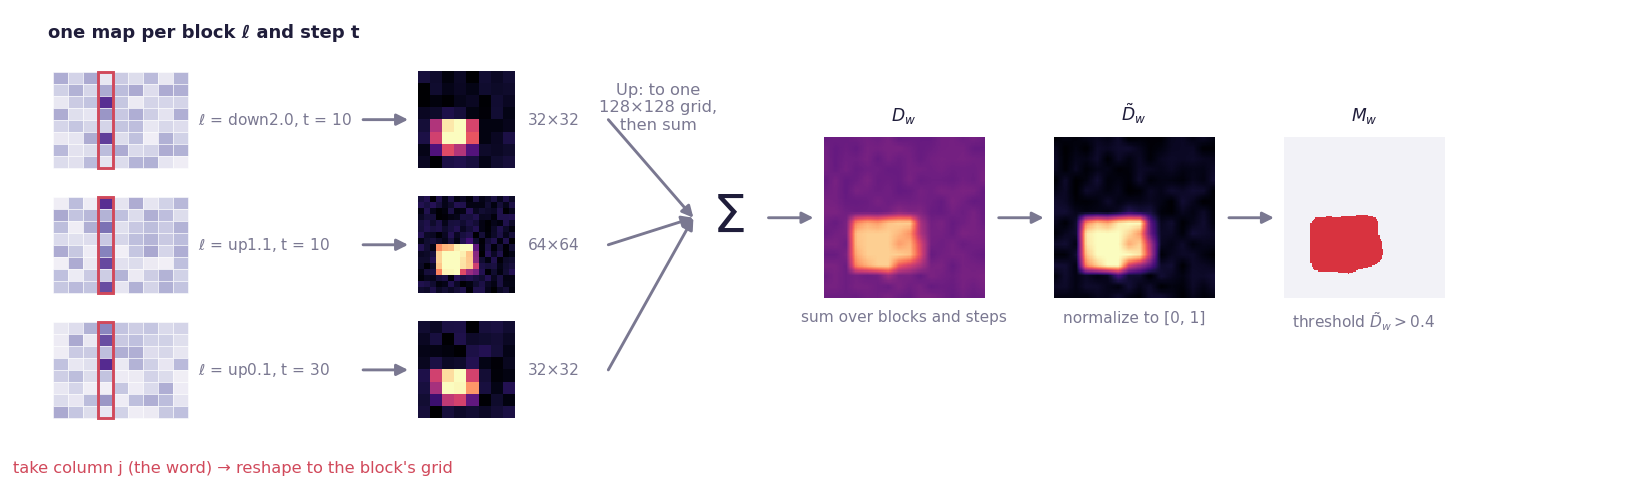

To compare two masks we use **intersection over union** (IoU):

$$\mathrm{IoU}(M_a, M_b) = \frac{|M_a \cap M_b|}{|M_a \cup M_b|} = \frac{\text{pixels in both masks}}{\text{pixels in at least one mask}}.$$

IoU = 1 means identical masks. IoU = 0 means no overlap. Two masks of the same size that share two thirds of
their pixels have IoU = 0.5. We use IoU in two ways:

* masks of **two words** (*Do similar objects merge?*): high IoU means attention to both words overlaps.
* a mask from **part of the run** (one step, one block) against the mask from the whole run (*When is the layout fixed?*, *Which blocks give the cleanest maps?*): high IoU means
  this part locates the word as the full run does.

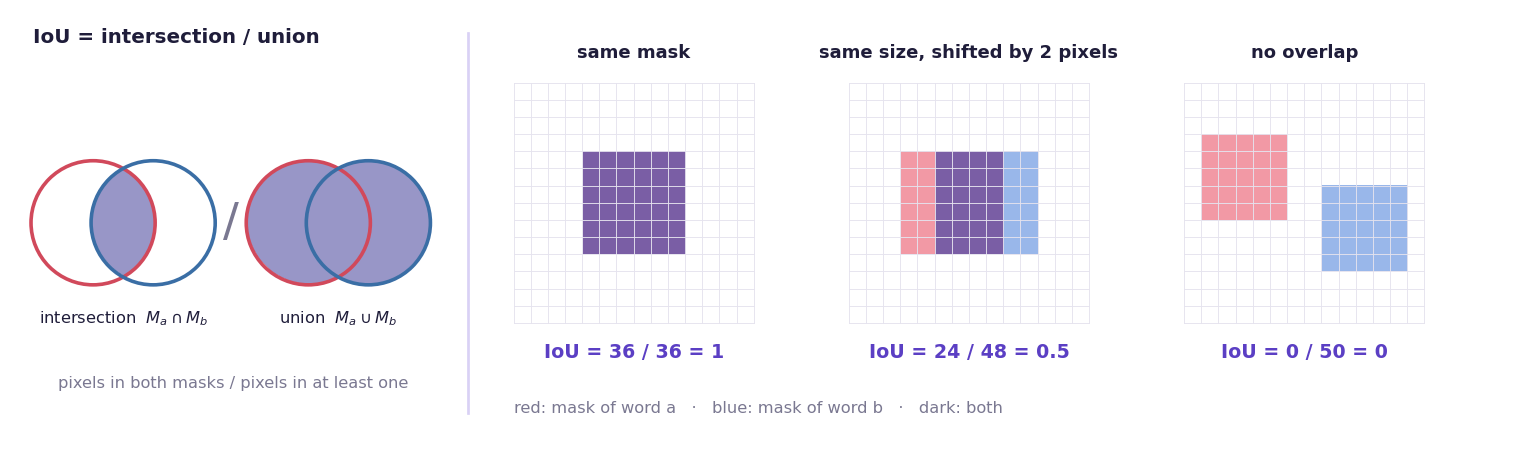

In [12]:
HEAT = 128   # common grid for heatmaps (= the latent size at 1024 px)


def word_positions(prompt, word):
    """Text positions of `word` in `prompt`. A word can be split into several tokens, so this is a list."""
    ids = tok(prompt).input_ids                                  # token ids of the prompt, with <sot> and <eos>
    w = tok(word, add_special_tokens=False).input_ids            # token ids of the word alone
    for i in range(len(ids)):                                    # find the word's tokens inside the prompt
        if ids[i:i + len(w)] == w:
            return list(range(i, i + len(w)))
    raise ValueError(f"{word!r} is not in {prompt!r}")


def to_grid(flat):
    """[N] -> [side, side]: a map over the N image patches as a square picture."""
    side = int(math.sqrt(flat.shape[0]))
    return flat.reshape(side, side)


def heatmap(prompt, word, blocks=None, steps=None):
    """Heatmap D_w of `word` in the last `generate` call: its maps summed over blocks and steps (None = all)."""
    pos = word_positions(prompt, word)
    total = torch.zeros(HEAT, HEAT)
    for (b, s), m in CROSS.items():
        if (blocks is None or b in blocks) and (steps is None or s in steps):   # only the chosen blocks and steps
            grid = to_grid(m[:, pos].sum(-1))                                    # the word's column, as a square map
            total += F.interpolate(grid[None, None], size=(HEAT, HEAT), mode="bilinear")[0, 0]   # upsample and add
    return total


def normalize(h):
    """Min-max normalize to [0, 1]."""
    return (h - h.min()) / (h.max() - h.min() + 1e-8)


def binarize(h, tau=0.4):
    """Word mask M_w: where the normalized heatmap is above tau."""
    return normalize(h) > tau


def iou(a, b):
    """Intersection over union of two boolean masks: |a and b| / |a or b|."""
    return float((a & b).sum() / (a | b).sum())

Plotting helpers (you can skip this cell).

In [14]:
def short(block):
    """Short block name for plots: 'up_blocks.1.attentions.2' -> 'up1.2'."""
    return (block.replace("down_blocks.", "down").replace("up_blocks.", "up")
                 .replace("mid_block", "mid").replace(".attentions.", "."))


def show_row(images, titles=None, size=2.8, suptitle=None):
    """Plot a row of PIL images with titles."""
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size + 0.4), squeeze=False)
    for ax, im, t in zip(axes[0], images, titles or [""] * len(images)):
        ax.imshow(im); ax.set_title(t, fontsize=9); ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()


def overlay(ax, img, heat, title=None, alpha=0.5):
    """Draw `img` with the normalized heatmap `heat` on top into the matplotlib axis `ax`."""
    h = F.interpolate(normalize(heat)[None, None], size=img.size[::-1], mode="bilinear")[0, 0]
    ax.imshow(img); ax.imshow(h, cmap="jet", alpha=alpha)
    ax.set_title(title, fontsize=10); ax.axis("off")


def show_word_maps(img, prompt, words, title=None, **kw):
    """Plot the image and the heatmap of each word in `words` (maps from the last `generate` call)."""
    fig, axes = plt.subplots(1, len(words) + 1, figsize=(2.8 * (len(words) + 1), 3))
    axes[0].imshow(img); axes[0].set_title("image", fontsize=10); axes[0].axis("off")
    for ax, w in zip(axes[1:], words):
        overlay(ax, img, heatmap(prompt, w, **kw), w)
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()

## 2. Where is each word drawn? (DAAM)

### What layers does SDXL have?

Before inspecting maps, we need to know where they come from. The SDXL U-Net ([SDXL](https://arxiv.org/abs/2307.01952)) denoises a latent of $128 \times 128$ (for a 1024 px image).

As we discussed before, U-Net contains residual and attn blocks. Attention exists only in the transformer blocks. 


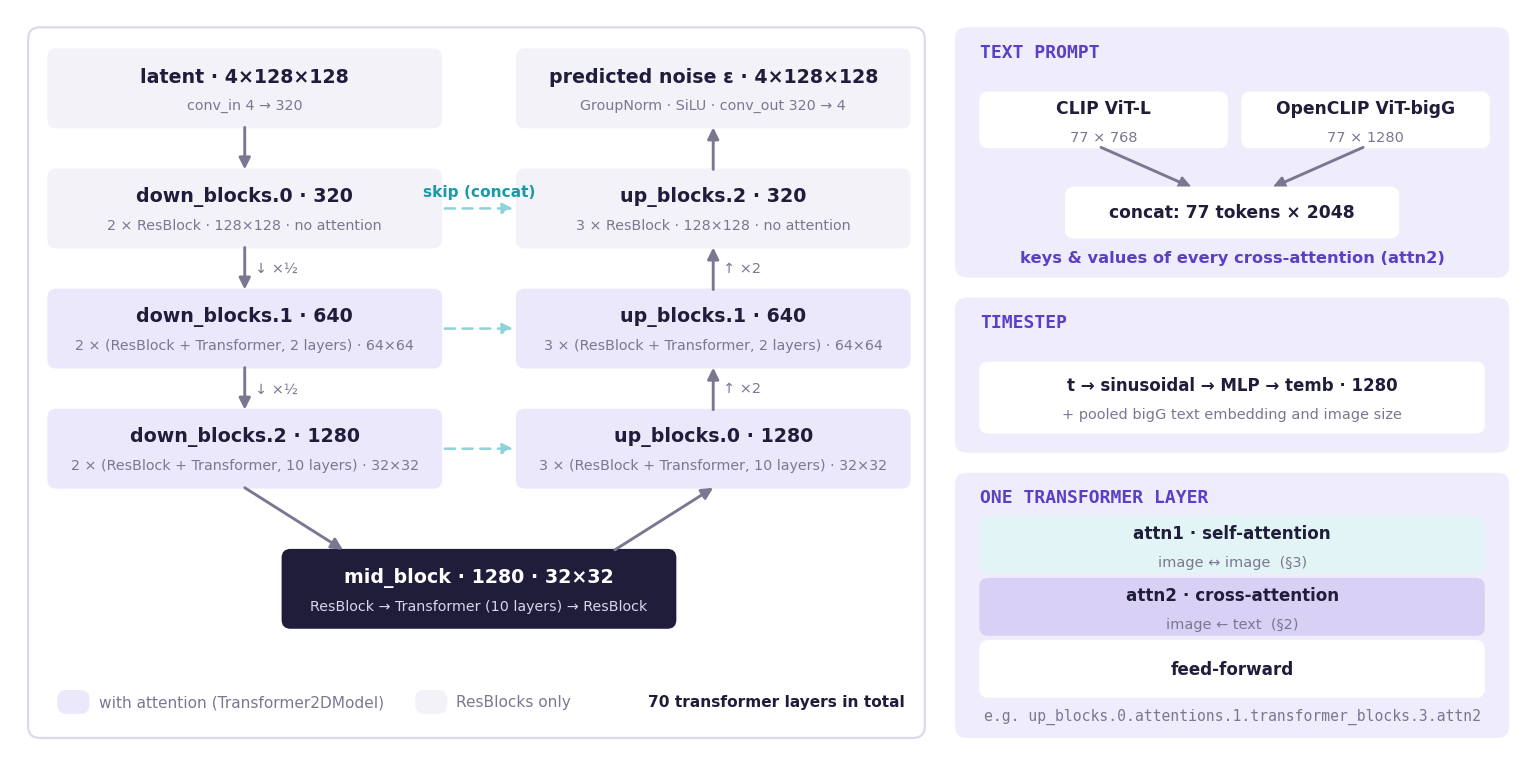

Let the processors record its maps, and show the size of each map and how many attn parts do we have.

In [16]:
PROMPT = "a red cube and a blue sphere on a wooden table"
img = generate(PROMPT)   # records the cross-attention maps of every block into CROSS

In [18]:
BLOCKS = [b for b, s in CROSS if s == 0]                                          # in the order the U-Net runs them
BLOCK_SIDE = {b: int(round(math.sqrt(CROSS[(b, 0)].shape[0]))) for b in BLOCKS}   # N = side x side patches
GRID = {b: f"{side}×{side}" for b, side in BLOCK_SIDE.items()}                     # e.g. "64×64", for plot labels

print(f"{'block':28s} {'short':7s} {'layers':>6s} {'channels':>8s} {'heads':>5s} {'grid':>7s}")
for b in BLOCKS:
    m = MODULES[b]
    print(f"{b:28s} {short(b):7s} {N_LAYERS[b]:6d} {m.config.in_channels:8d} "
          f"{m.transformer_blocks[0].attn1.heads:5d} {GRID[b]:>7s}")
print("text context:", CTX_LEN, "positions x", pipe.unet.config.cross_attention_dim, "dims (two CLIP encoders concatenated)")

block                        short   layers channels heads    grid
down_blocks.1.attentions.0   down1.0      2      640    10   64×64
down_blocks.1.attentions.1   down1.1      2      640    10   64×64
down_blocks.2.attentions.0   down2.0     10     1280    20   32×32
down_blocks.2.attentions.1   down2.1     10     1280    20   32×32
mid_block.attentions.0       mid.0       10     1280    20   32×32
up_blocks.0.attentions.0     up0.0       10     1280    20   32×32
up_blocks.0.attentions.1     up0.1       10     1280    20   32×32
up_blocks.0.attentions.2     up0.2       10     1280    20   32×32
up_blocks.1.attentions.0     up1.0        2      640    10   64×64
up_blocks.1.attentions.1     up1.1        2      640    10   64×64
up_blocks.1.attentions.2     up1.2        2      640    10   64×64
text context: 77 positions x 2048 dims (two CLIP encoders concatenated)


Most layers are in the $32 \times 32$ blocks, with 10 layers each. The $64 \times 64$ blocks have only 2 each.
Every cross-attention layer uses the same 77 text token positions, with outputs from SDXL's two CLIP text encoders
concatenated.

### Cross-attn in SDXL

Cross-attention is how the prompt gets into the image. The text encoders turn the prompt into 77 token vectors. 

In every cross-attention layer, every image patch $i$ looks at these tokens in two steps:

1. **Where to look.** The patch has a query $q_i$, and every token $j$ has a key $k_j$. Their similarity, passed through a softmax over the 77 tokens, gives the attention weights

$$A_{ij} = \operatorname{softmax}_j\big(q_i \cdot k_j / \sqrt d\big)$$


2. **What to take.** Every token also has a value $v_j$, and the patch receives their weighted mix: 

$$\text{out}_i = \sum_j A_{ij}\, v_j$$

So the map $A$ has one row per patch ($N = H \cdot W$ rows) and one column per token (77 columns). A **row** shows which words one patch reads. A **column** shows which patches read one word.

Self-attention works the same way, but its keys and values come from the image patches instead of the text.

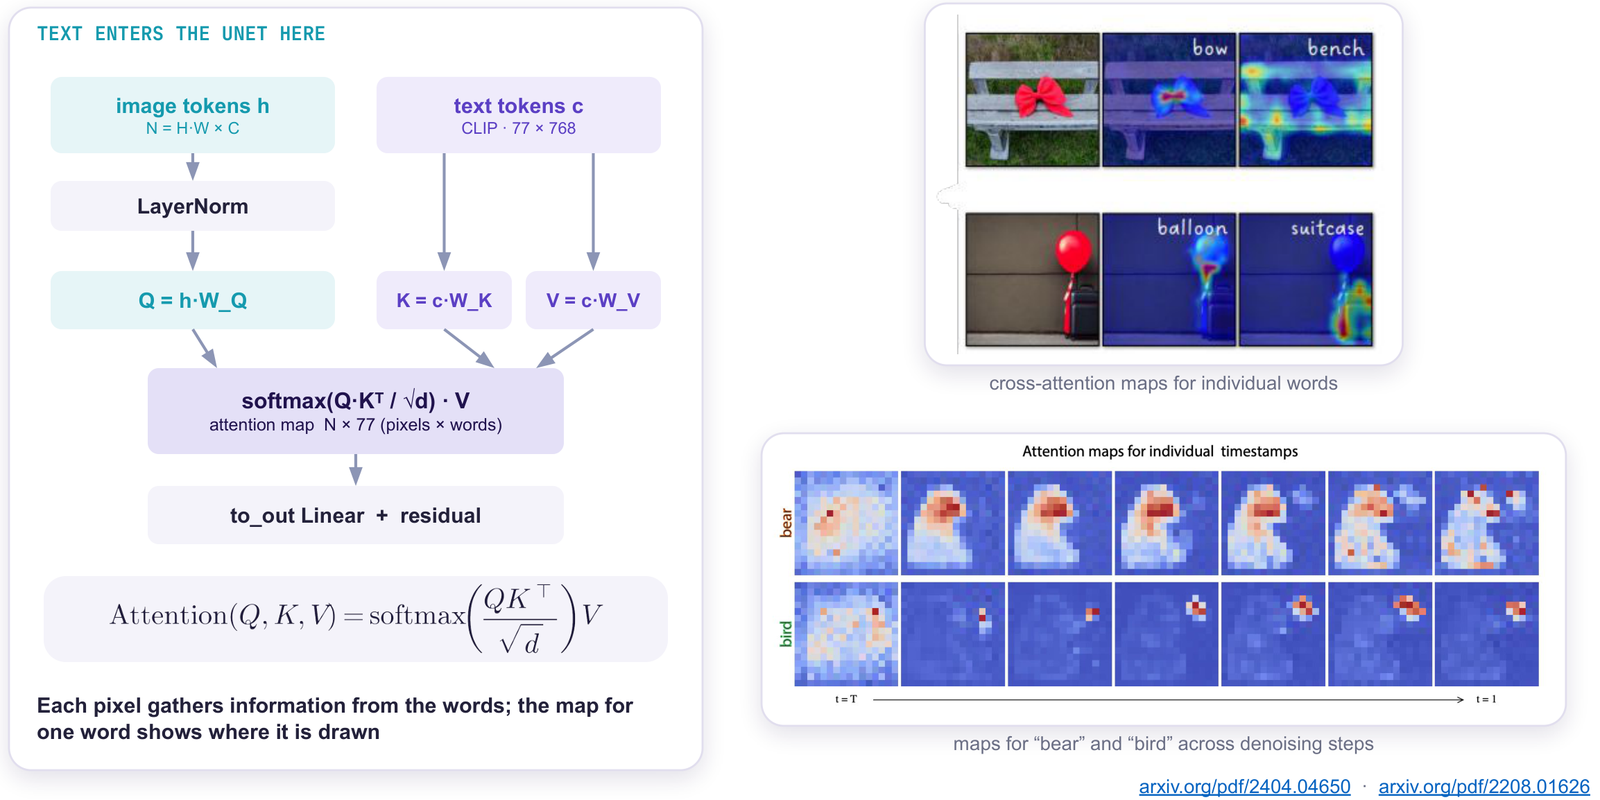

[DAAM](https://arxiv.org/abs/2210.04885) builds one heatmap per word from these
columns. A single column of a single layer is coarse and noisy. So DAAM takes the word's
column in **every** cross-attention layer and at **every** denoising step, upsamples them to one size and adds them up. 

The result shows where the word was drawn, and a threshold turns it into a mask of the object, without any training or extra model.

The figure shows these steps for the word *cube*.

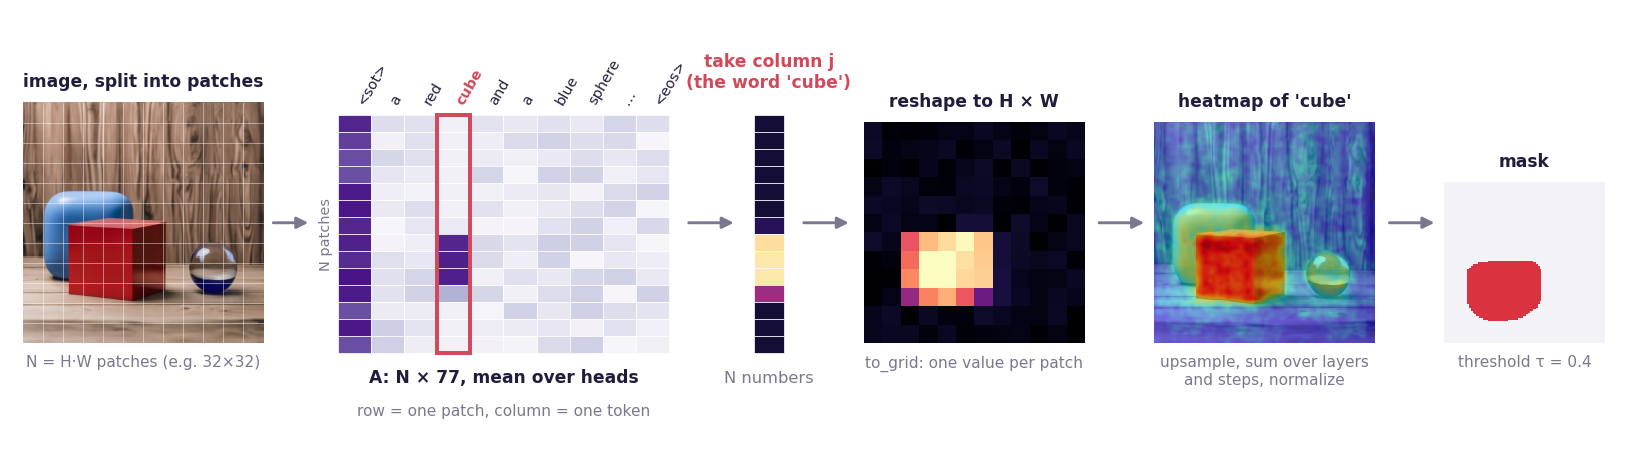

### Which parts of the image react to each word?

We overlay each word’s heatmap $\tilde D_w$ on the image. Look for the following:

* nouns (*cube*, *sphere*, *table*) should have compact maps on their objects. DAAM’s user study rated noun, verb and adjective maps good, but numeral and adverb maps only fair.
* colour words often spread far beyond their objects.
* each map is normalized separately, so all maps have a hot spot. Check that it falls on the right object. For a wrongly drawn object, the map usually follows what appeared instead.

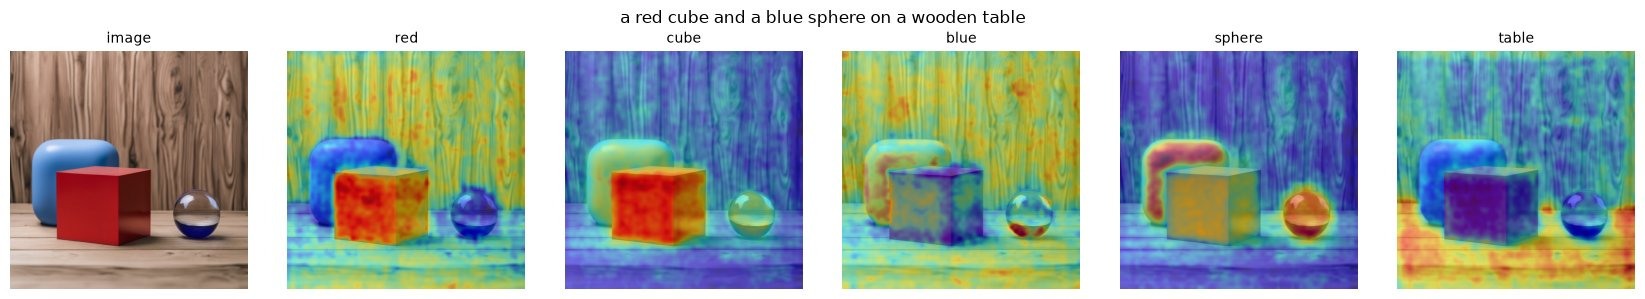

In [20]:
# Plot the image and the heatmap of each word in the prompt.
show_word_maps(img, PROMPT, ["red", "cube", "blue", "sphere", "table"], title=PROMPT)

### Attribute leakage: does "red" leak onto the sphere?

**Attribute leakage** means that a property of one object ends up on another. In our prompt the cube should be red and the sphere blue, but sometimes the sphere comes out red too, or the two colours swap. 

How could attention cause it? A patch of the sphere attends to all tokens of the prompt, not only to *blue* and *sphere*. If it also attends to *red*, it receives the value vector of *red* ($\text{out} = AV$), and the sphere gets a red tint.

So we look at the heatmap of *red*: does it stay on the cube, or does it also lie on the sphere? 

Below are six seeds of our prompt: the image, the heatmap of *red* and the heatmap of *blue*.

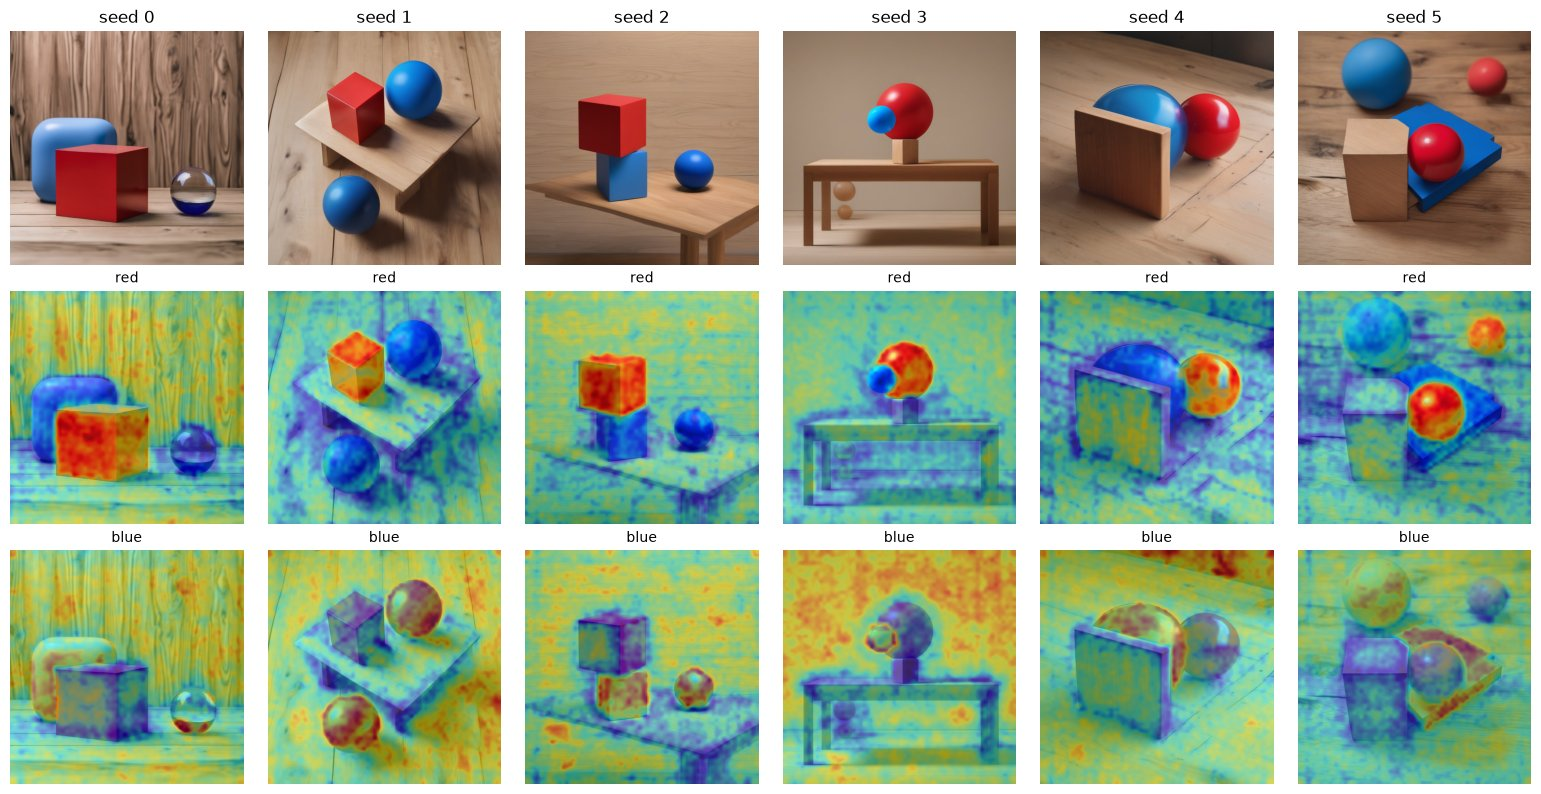

In [22]:
SEEDS = range(6)
fig, axes = plt.subplots(3, len(SEEDS), figsize=(2.6 * len(SEEDS), 8))   # rows: image, map of "red", map of "blue"
for j, seed in enumerate(SEEDS):
    im = generate(PROMPT, seed=seed)                     # also records the maps of this run
    axes[0, j].imshow(im); axes[0, j].set_title(f"seed {seed}"); axes[0, j].axis("off")
    overlay(axes[1, j], im, heatmap(PROMPT, "red"), "red")
    overlay(axes[2, j], im, heatmap(PROMPT, "blue"), "blue")
plt.tight_layout(); plt.show()

**What we see.**

* In seeds 0–2 the colours are right, and the map of *red* lies on the red cube.
* In seeds 3–5 the binding failed: the sphere is red, and the cube is wooden or tiny. The map of *red* now lies on the
  red sphere. The word *red* is read where red was drawn, not where the *cube* is.
* The map of *blue* spreads over the table and the background. DAAM calls this *adjective entanglement*: colour words
  are read far beyond their object.

### Do similar objects merge?

DAAM found that prompts with two objects of the same kind such as *a giraffe and a zebra*, often give only one of the two, or a hybrid such as a striped giraffe. Their maps overlap much more than those of unrelated objects. Greater overlap means more missing objects.

Why? Similar words have similar embeddings, so their keys are close, and a patch that attends to *giraffe* also attends to *zebra*. Then both animals get features of both words.

We measure the overlap of the two masks, $\mathrm{IoU}(M_\text{giraffe}, M_\text{zebra})$. 

Low IoU means that each word got its own region. High IoU means that the same patches attend to both words, so expect a hybrid or a missing animal.

The bottom row shows the two masks on the image: **red** is only the giraffe mask, **blue** only the zebra mask, and
**purple** is their intersection. IoU is the purple area divided by the whole coloured area.

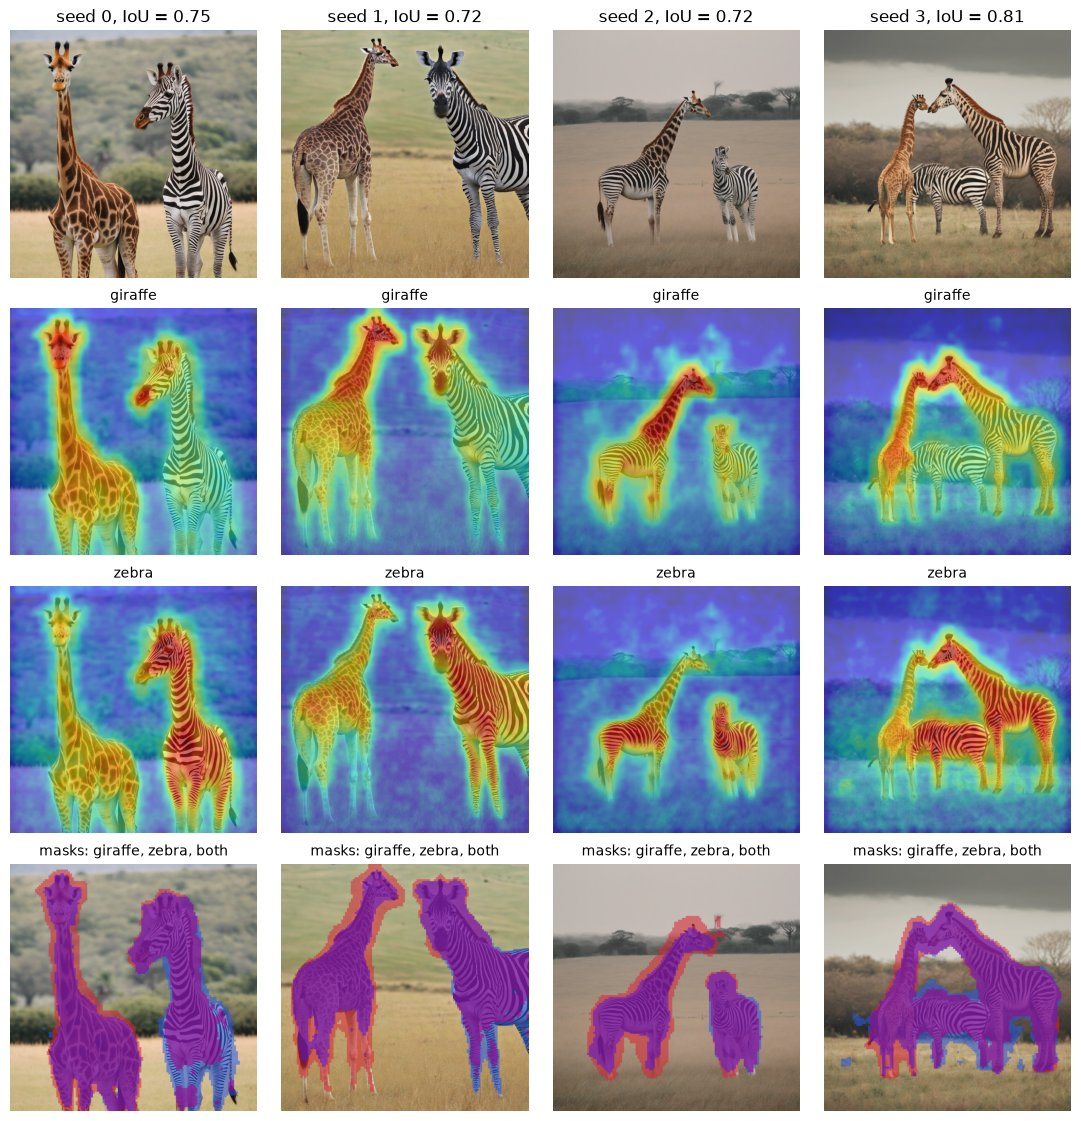

In [24]:
def show_masks(ax, img, ma, mb, title=None):
    """Two boolean masks on top of `img`: red = only ma, blue = only mb, purple = both (the intersection)."""
    a, b = (F.interpolate(m[None, None].float(), size=img.size[::-1], mode="nearest")[0, 0].numpy() > 0 for m in (ma, mb))
    rgba = np.zeros((*a.shape, 4))
    rgba[a & ~b], rgba[b & ~a], rgba[a & b] = (0.85, 0.15, 0.2, 0.55), (0.15, 0.35, 0.9, 0.55), (0.5, 0.1, 0.65, 0.8)
    ax.imshow(img); ax.imshow(rgba); ax.set_title(title, fontsize=10); ax.axis("off")


P_MERGE = "a giraffe and a zebra in a field"
fig, axes = plt.subplots(4, 4, figsize=(11, 11.3))      # rows: image, map of giraffe, map of zebra, the two masks
for j, seed in enumerate(range(4)):
    im = generate(P_MERGE, seed=seed)
    hg, hz = heatmap(P_MERGE, "giraffe"), heatmap(P_MERGE, "zebra")
    mg, mz = binarize(hg), binarize(hz)
    axes[0, j].imshow(im); axes[0, j].axis("off")
    axes[0, j].set_title(f"seed {seed}, IoU = {iou(mg, mz):.2f}")
    overlay(axes[1, j], im, hg, "giraffe"); overlay(axes[2, j], im, hz, "zebra")
    show_masks(axes[3, j], im, mg, mz, "masks: giraffe, zebra, both")
plt.tight_layout(); plt.show()

### Does syntax show up in the maps?

In a dependency parse, every word depends on a **head** word. In *a dog wearing a
hat*, *hat* is the object of the verb *wearing* and *dog* is its subject. In *a red car*, *red* modifies *car*. The
model was trained only on image–caption pairs. Do the maps of linked words still follow a consistent pattern?

DAAM measured how much the mask of one word contains the mask of another:

$$\mathrm{cov}(A \supseteq B) = \frac{|M_A \cap M_B|}{|M_B|} \qquad (1 = \text{the mask of } B \text{ lies inside the mask of } A).$$

Averaged over many prompts, they found:

* **verb ⊇ object, verb ⊇ subject**: the map of a verb covers its object and its subject. The action is drawn around
  the things that take part in it.
* **adjective ⊇ noun**: the map of an adjective covers its noun, not the other way round. DAAM calls this
  counterintuitive; it is the same wide spread of adjectives as in *Attribute leakage*.

These are averages, so single prompts can disagree. We check one example of each relation.

The last panel shows how the numbers are computed: **red** is only the mask of the first word, **blue** only the
mask of the second, **purple** both. $\mathrm{cov}(A \supseteq B)$ is the purple area divided by the whole mask of
$B$ (its blue and purple part): the share of $B$ that lies inside $A$.

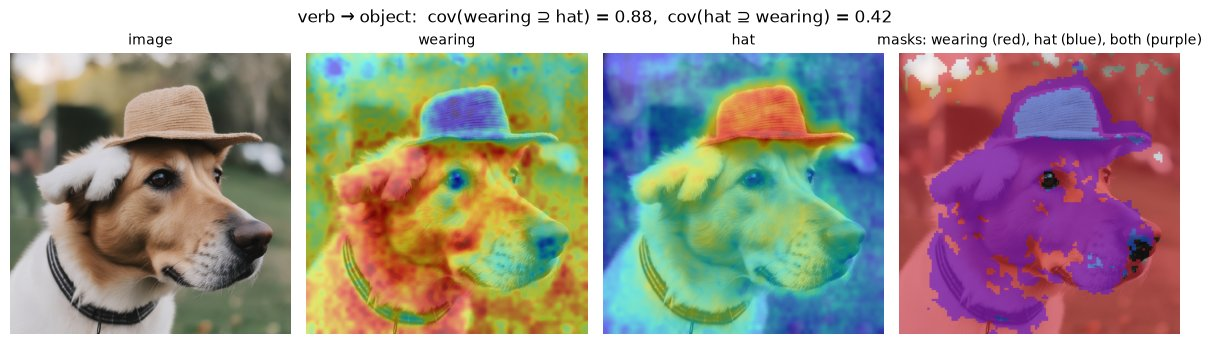

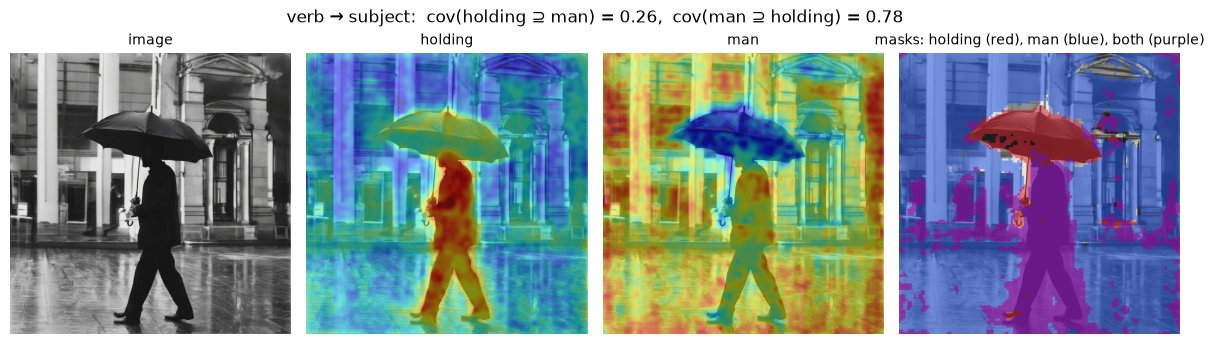

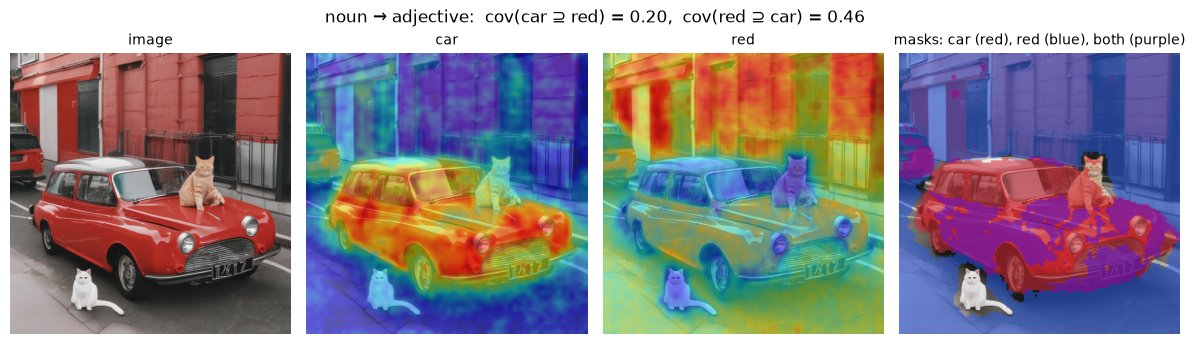

In [26]:
def coverage(prompt, big, small):
    """cov(big ⊇ small) = |M_big ∩ M_small| / |M_small| for two words of `prompt` (maps from the last `generate`)."""
    a, b = binarize(heatmap(prompt, big)), binarize(heatmap(prompt, small))
    return float((a & b).sum() / (b.sum() + 1e-8))       # share of the small mask inside the big one


for prompt, head, dep, relation in [("a dog wearing a hat", "wearing", "hat", "verb → object"),
                                    ("a man holding an umbrella", "holding", "man", "verb → subject"),
                                    ("a cat sitting on a red car", "car", "red", "noun → adjective")]:
    im = generate(prompt)
    hh, hd = heatmap(prompt, head), heatmap(prompt, dep)
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
    axes[0].imshow(im); axes[0].set_title("image", fontsize=10); axes[0].axis("off")
    overlay(axes[1], im, hh, head); overlay(axes[2], im, hd, dep)
    show_masks(axes[3], im, binarize(hh), binarize(hd), f"masks: {head} (red), {dep} (blue), both (purple)")
    fig.suptitle(f"{relation}:  cov({head} ⊇ {dep}) = {coverage(prompt, head, dep):.2f},  "
                 f"cov({dep} ⊇ {head}) = {coverage(prompt, dep, head):.2f}")
    plt.tight_layout(); plt.show()

### When is the layout fixed?

Denoising goes from pure noise to the image in $T$ steps. The model is known to decide coarse structure early and
details late. [eDiff-I](https://arxiv.org/abs/2211.01324) even trains separate denoisers for early and late steps. The
maps let us see this for every word.

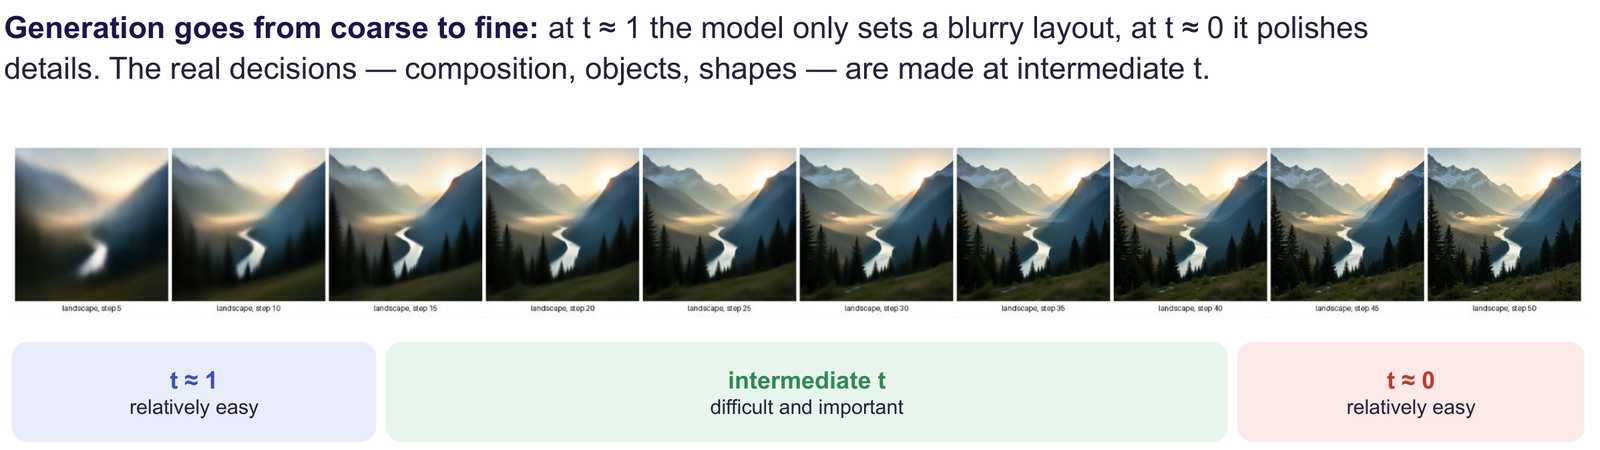

**How to read the grid below.** Each column is one denoising step. The top row is $\hat x_0$, the model's guess of the
final image at this step (the scheduler computes it at every step; we store it in `X0` and decode it with the tiny
TAESD decoder). Every other row is one block, and each picture is the cross-attention map of *cube* **in this block at
this step only**. These are not block outputs: they show where the patches of this block read the word *cube*.

In [28]:
X0 = {}   # step -> the model's guess x0_hat of the clean latent at this step (of the last generation)


def step_and_keep_x0(*args, **kwargs):
    """The scheduler's own step; it also stores the x0_hat that the step computes anyway (its second output)."""
    if RUN["step"] == 0:                                                # a new generation: forget the old one
        X0.clear()
    out = type(pipe.scheduler).step(pipe.scheduler, *args, **kwargs)   # the original method of the scheduler class
    X0[RUN["step"]] = out[1] if isinstance(out, tuple) else out.pred_original_sample
    return out


pipe.scheduler.step = step_and_keep_x0     # from now on, every generation fills X0


def preview(latent):
    """Decode a latent with the tiny TAESD decoder -> PIL image (cheap, slightly blurry)."""
    x = taesd.decode(latent.to(taesd.device, taesd.dtype)).sample
    return pipe.image_processor.postprocess(x, output_type="pil")[0]

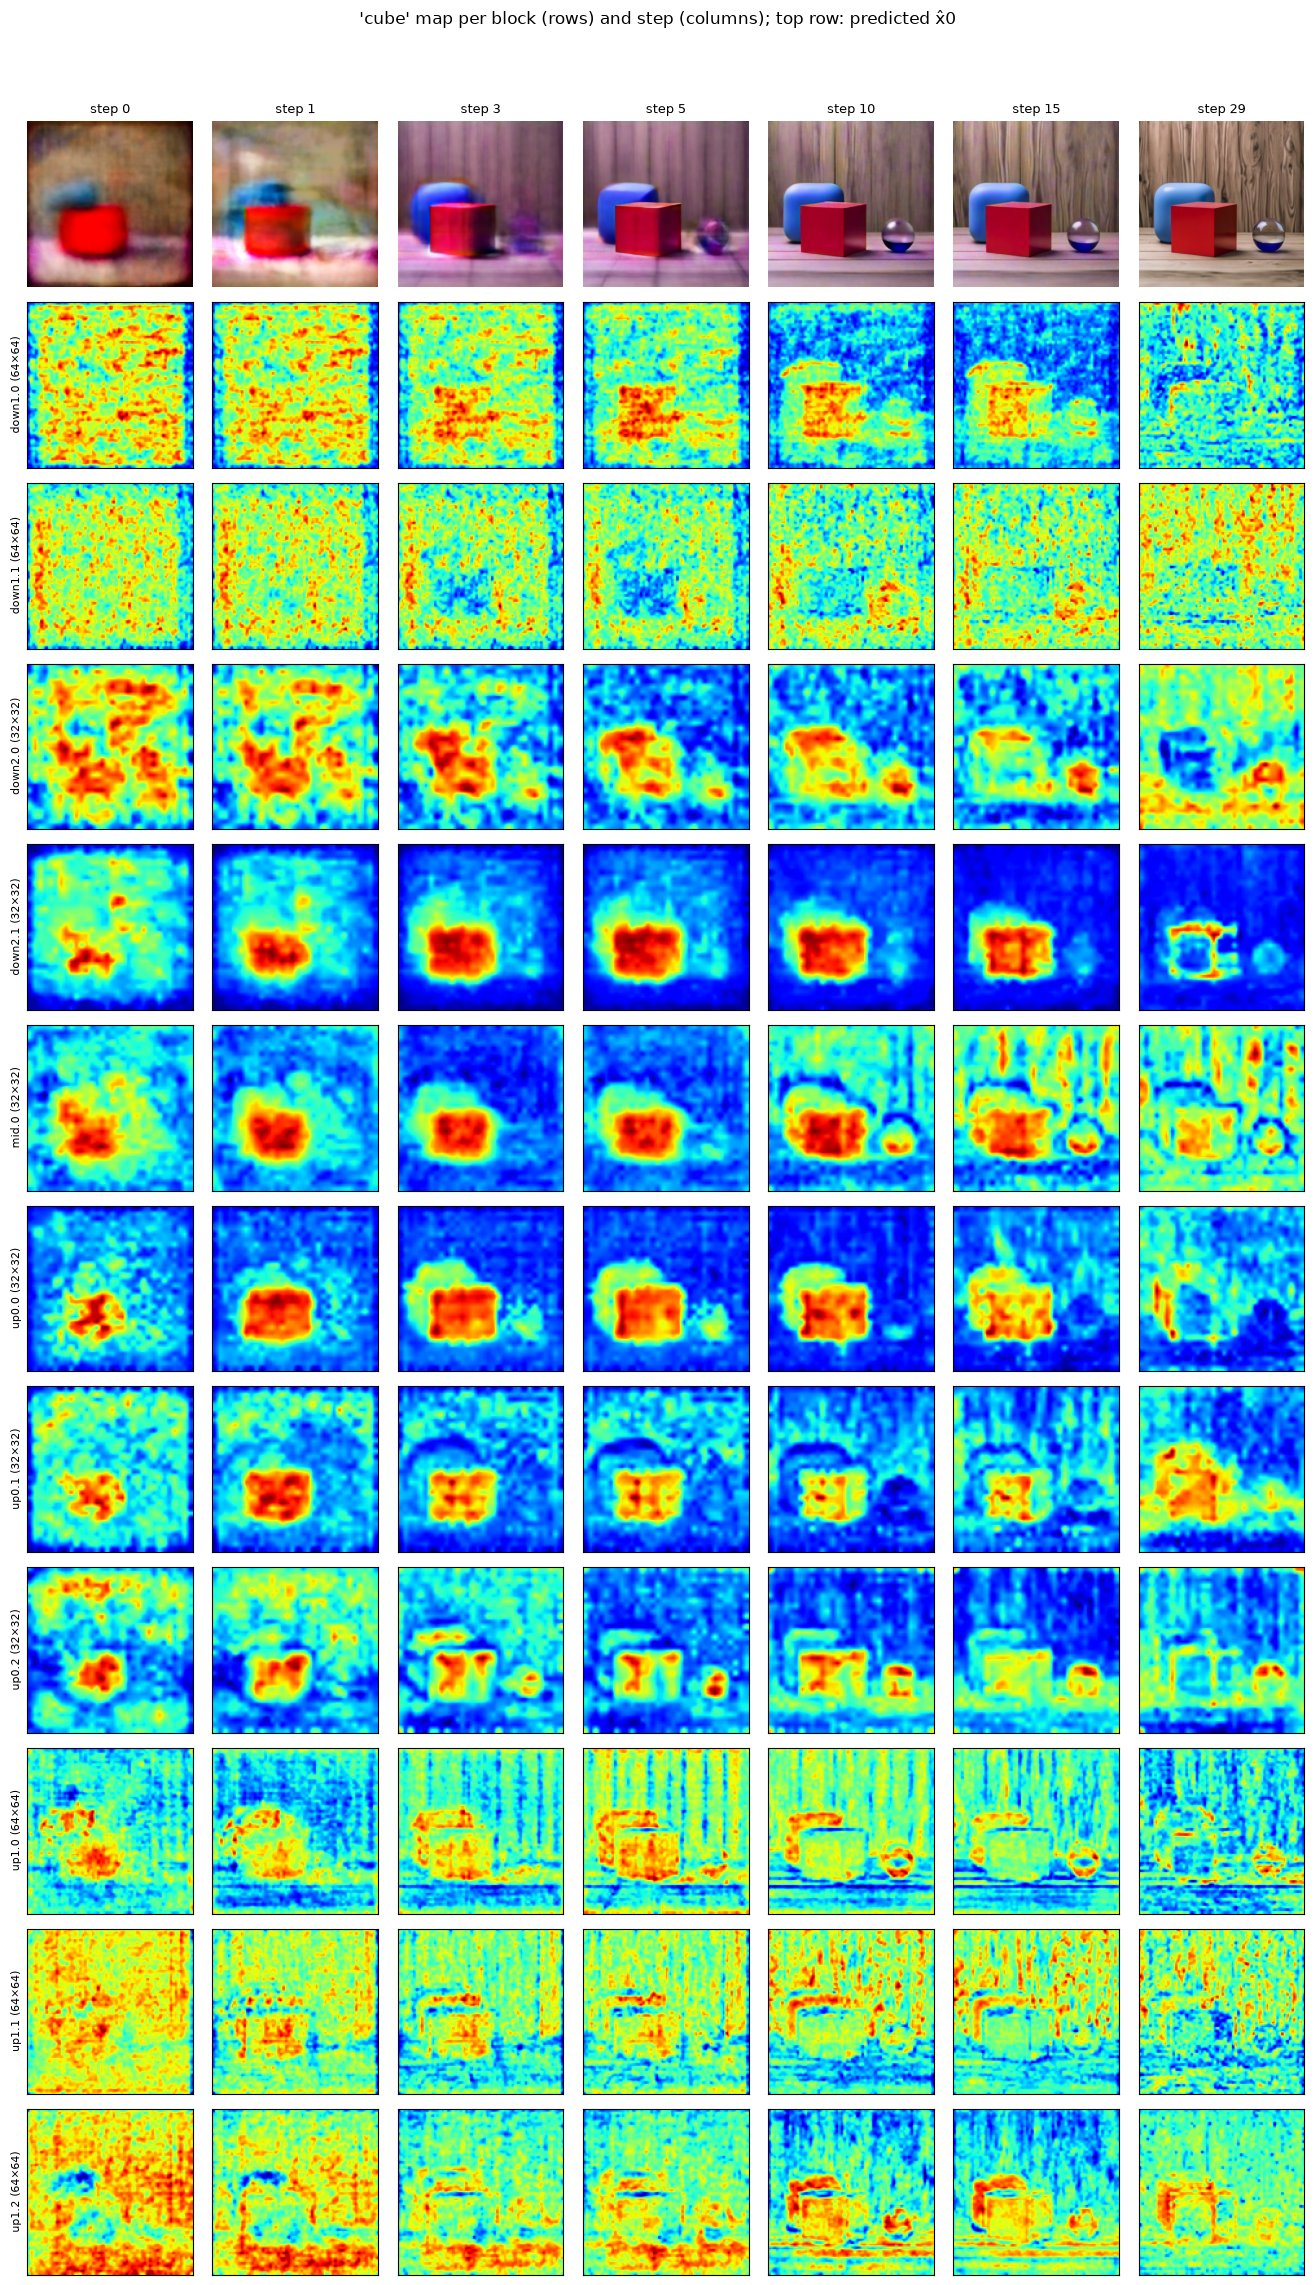

In [30]:
img = generate(PROMPT)
SHOW_STEPS = sorted({0, 1, 3, STEPS // 6, STEPS // 3, STEPS // 2, STEPS - 1})
WORD = "cube"
fig, axes = plt.subplots(len(BLOCKS) + 1, len(SHOW_STEPS), figsize=(1.9 * len(SHOW_STEPS), 1.9 * (len(BLOCKS) + 1)))
for j, s in enumerate(SHOW_STEPS):
    axes[0, j].imshow(preview(X0[s])); axes[0, j].set_title(f"step {s}", fontsize=9); axes[0, j].axis("off")
    for i, g in enumerate(BLOCKS):
        ax = axes[i + 1, j]
        ax.imshow(normalize(heatmap(PROMPT, WORD, blocks={g}, steps={s})), cmap="jet")
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(f"{short(g)} ({GRID[g]})", fontsize=8)
fig.suptitle(f"'{WORD}' map per block (rows) and step (columns); top row: predicted x̂0", y=1.0)
plt.tight_layout(rect=(0, 0, 1, 0.98)); plt.show()

**What we see.** In the $32 \times 32$ blocks (down2.1, mid, up0.x) the cube is already in place at steps 1–3, while
$\hat x_0$ is still a blurry blob. The $64 \times 64$ blocks give noisy maps that later follow edges. At the last steps
most maps lose the object: the model only refines texture by then.

We compare each step’s mask with the mask from all steps:

$$\mathrm{IoU}\big(M^{(t)}_w,\ M_w\big), \qquad M^{(t)}_w = \text{mask from step } t \text{ only}, \quad M_w = \text{mask from all steps}.$$

First for the steps shown above: **red** is the mask from step $t$ only, **blue** the mask from all steps, **purple**
both. IoU is the purple area divided by the whole coloured area.

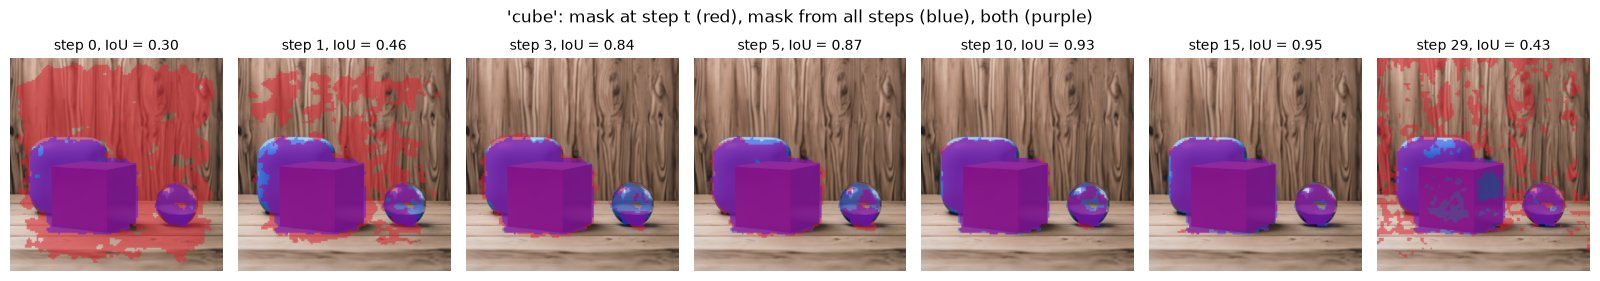

In [32]:
final = binarize(heatmap(PROMPT, WORD))                    # mask from all steps and blocks of the run above
fig, axes = plt.subplots(1, len(SHOW_STEPS), figsize=(2.3 * len(SHOW_STEPS), 2.9))
for ax, s in zip(axes, SHOW_STEPS):
    m = binarize(heatmap(PROMPT, WORD, steps={s}))         # mask from step s only (all blocks)
    show_masks(ax, img, m, final, f"step {s}, IoU = {iou(m, final):.2f}")
fig.suptitle(f"'{WORD}': mask at step t (red), mask from all steps (blue), both (purple)")
plt.tight_layout(); plt.show()

Now the same IoU for **every** step, as a curve. When the curve levels off, the model has decided where the object
goes. One line uses all blocks, the other two only the $32 \times 32$ or only the $64 \times 64$ blocks.

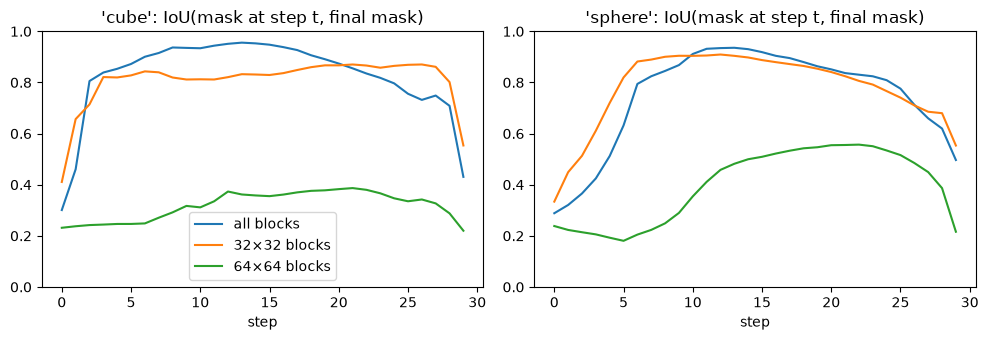

In [34]:
run_steps = sorted({s for _, s in CROSS})      # steps of the last generation
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, word in zip(axes, ["cube", "sphere"]):
    final = binarize(heatmap(PROMPT, word))                                    # mask from all steps and blocks
    curves = {"all blocks": None, **{f"{side}×{side} blocks": {b for b in BLOCKS if BLOCK_SIDE[b] == side}
                                     for side in sorted(set(BLOCK_SIDE.values()))}}   # label -> set of blocks
    for label, gs in curves.items():                                          # one curve: IoU at every step
        ax.plot(run_steps, [iou(binarize(heatmap(PROMPT, word, blocks=gs, steps={s})), final) for s in run_steps], label=label)
    ax.set_title(f"'{word}': IoU(mask at step t, final mask)"); ax.set_xlabel("step"); ax.set_ylim(0, 1)
axes[0].legend(); plt.tight_layout(); plt.show()

**What we see.** For the cube, the IoU of all blocks passes 0.8 by step 2–3 and stays high: the place of the cube is
decided in the first tenth of the steps. The sphere follows a few steps later. At the very last steps the IoU drops,
because the maps turn into edges and texture. The $64 \times 64$ blocks alone never match the final mask well.

### Which blocks give the cleanest maps?

Now compare the mask $M^{[\ell]}_w$ from block $\ell$, summed over all steps, with the full-run mask:
$\mathrm{IoU}\big(M^{[\ell]}_w, M_w\big)$. This tells us which single block to use for a mask. It also suggests which
blocks matter for Part B’s edits and patches.

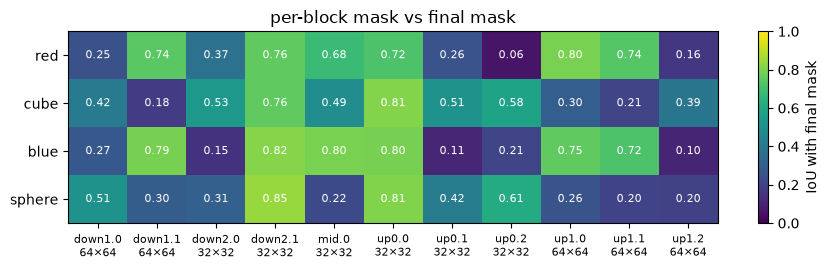

In [36]:
words = ["red", "cube", "blue", "sphere"]
# scores[i, j] = IoU(mask of word i from block j only, mask of word i from all blocks)
scores = np.array([[iou(binarize(heatmap(PROMPT, w, blocks={g})), binarize(heatmap(PROMPT, w))) for g in BLOCKS]
                   for w in words])
plt.figure(figsize=(9, 2.8))
plt.imshow(scores, cmap="viridis", vmin=0, vmax=1, aspect="auto")
plt.yticks(range(len(words)), words)
plt.xticks(range(len(BLOCKS)), [f"{short(g)}\n{GRID[g]}" for g in BLOCKS], fontsize=8)
for i in range(len(words)):
    for j in range(len(BLOCKS)):
        plt.text(j, i, f"{scores[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
plt.colorbar(label="IoU with final mask"); plt.title("per-block mask vs final mask"); plt.tight_layout(); plt.show()

### Tasks §2

**2.1. Which words have a map?** Generate `"three apples and a dog running quickly on the grass"` and call
`show_word_maps` for `["three", "apples", "dog", "running", "quickly", "grass"]`. Sort the words into *compact map*,
*diffuse map*, *no clear map*. Which parts of speech can be localized? Does this agree with DAAM (numerals and
adverbs are the worst)?

In [38]:
# Task 2.1: your code

**2.2. Does overlap predict a missing object?** For `P_MERGE` and 10 seeds, record the animals’ mask IoU and inspect
each image to see whether both animals are present. Compare the mean IoU of the "both present" and "one missing /
merged" groups.

In [40]:
# Task 2.2: your code

**2.3. Fewer steps, no guidance.** Rerun *When is the layout fixed?* with `generate(PROMPT, steps=15)` and with `guidance=1.0`. Plot the IoU
curves. Is the layout fixed after the same *number* of steps or the same *fraction* of the trajectory?

In [42]:
# Task 2.3: your code

## 3. What does self-attention encode?

Cross-attention shows which words a patch attends to. Self-attention shows which other patches it attends to, without direct input from words. If patches of the same object mostly attend to each other, self-attention represents the image’s **shape and layout**. [DiffSeg](https://arxiv.org/abs/2308.12469) uses this for segmentation without labels, and [Plug-and-Play](https://arxiv.org/abs/2211.12572) copies self-attention features to keep the structure of an image while editing it.

Reminder of self-attention: queries, keys and values all come from the image tokens, so the map is N × N: every patch against every patch.

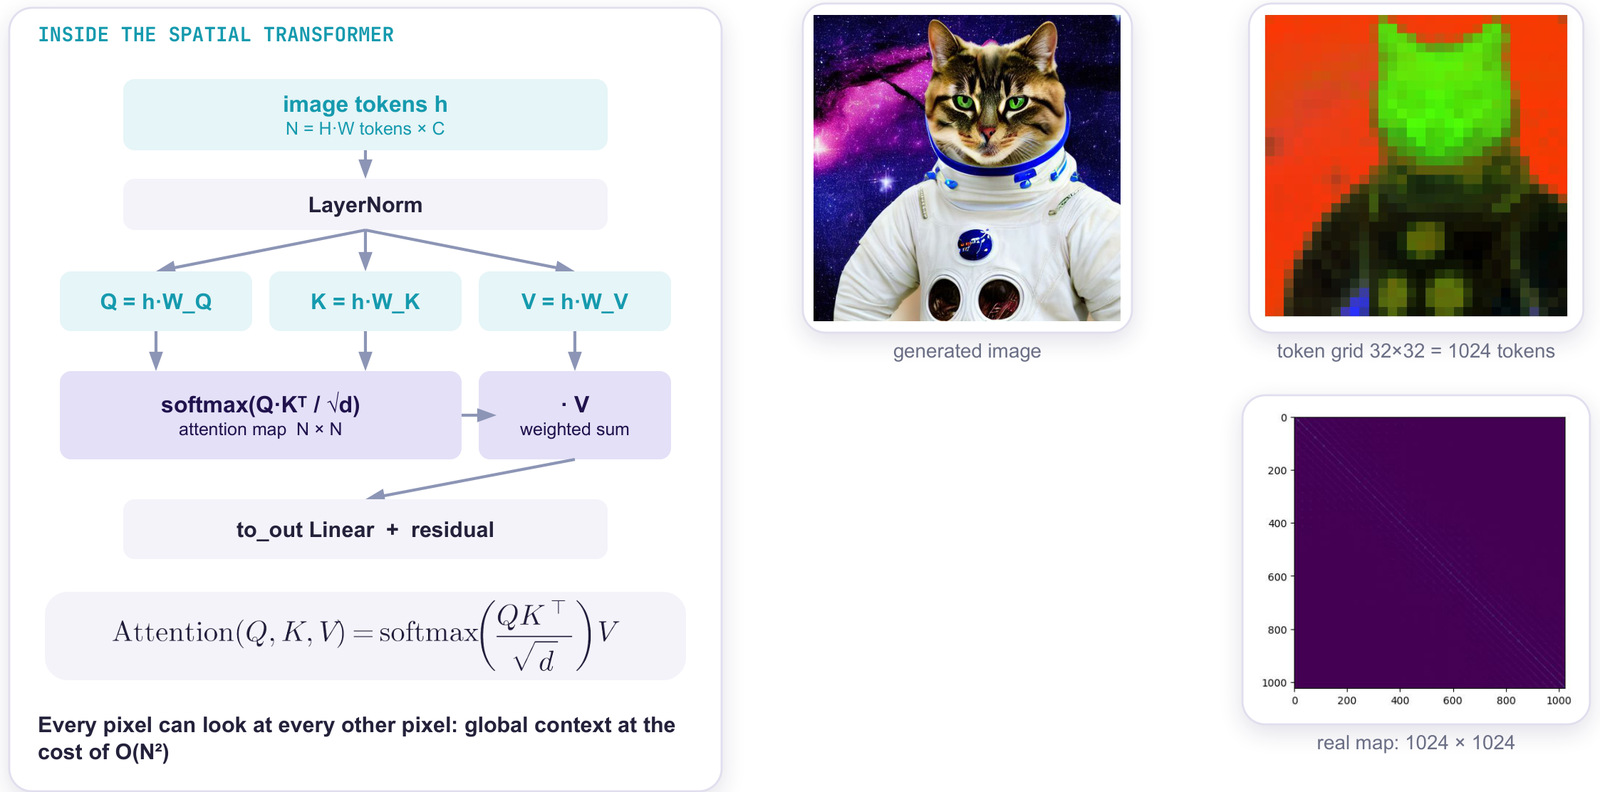

We record the self-attention $A^{\text{self}} \in \mathbb R^{N\times N}$ of the up (decoder) blocks, averaged over the middle third of the steps: by then the layout is fixed, but details have yet to appear. 

Row $i$ describes patch $i$ by *what it attends to*. 

A $64 \times 64$ self-attention map has $4096 \times 4096$ entries per head, so we build it only in the blocks we need (`self_blocks=UP`).

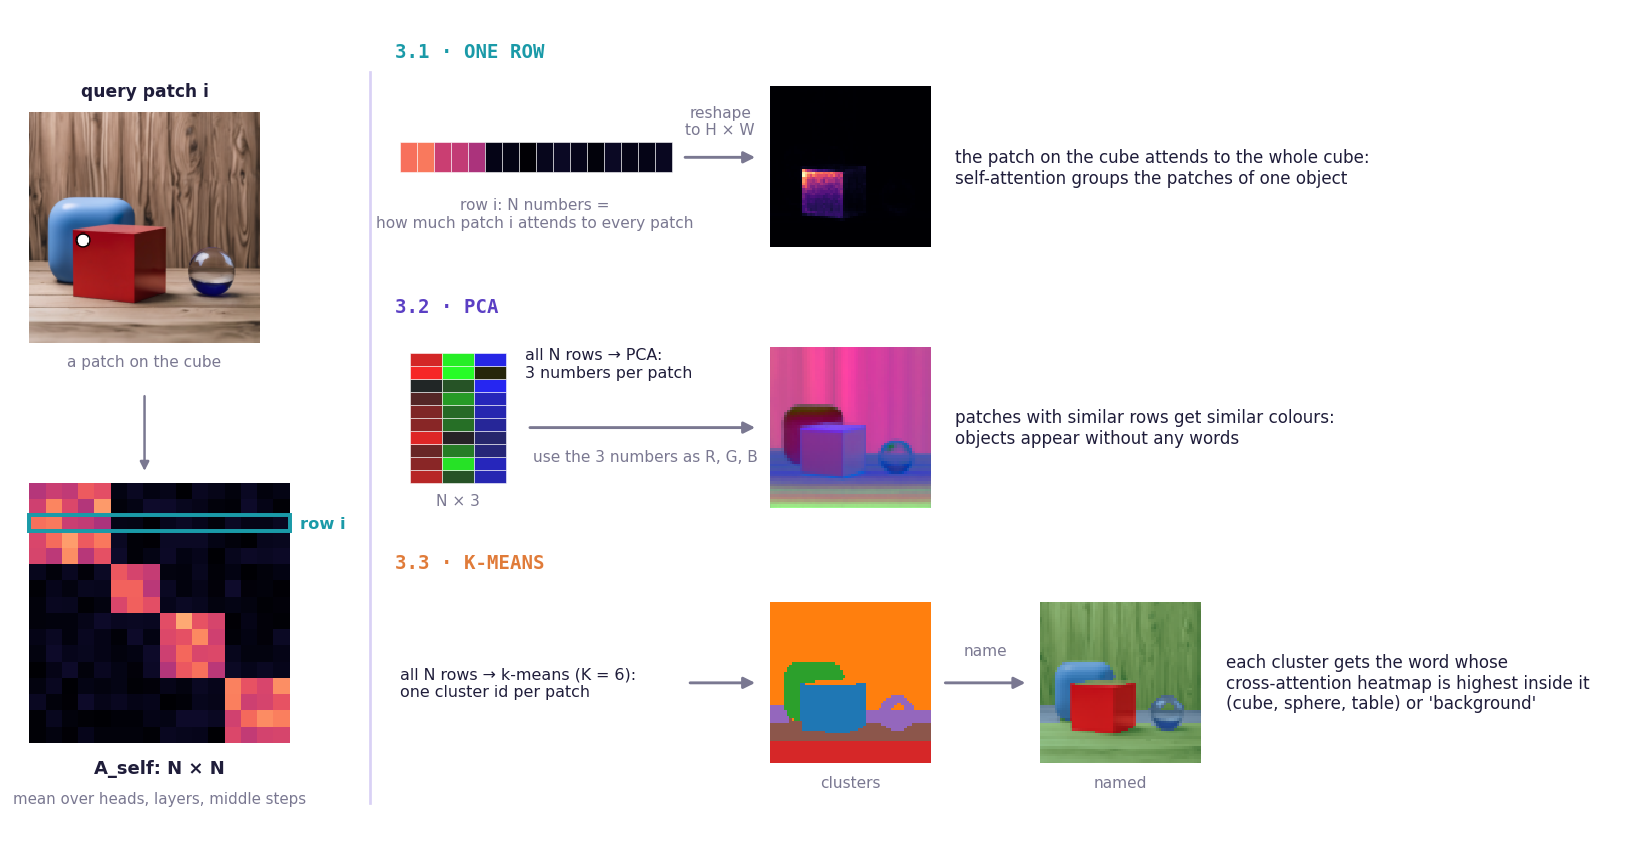

In [50]:
UP = [b for b in BLOCKS if b.startswith("up_blocks")]       # the decoder blocks
SELF_STEPS = set(range(STEPS // 3, 2 * STEPS // 3))          # the middle third of the steps
SELF = {}    # block -> [N, N] self-attention map, mean over heads, layers and SELF_STEPS


def record_self(A, info):
    """Edit that changes nothing: adds the prompt-branch self-attention map (steps in SELF_STEPS) to SELF."""
    if not info["cross"] and info["step"] in SELF_STEPS:
        m = A[info["cond"]].mean(dim=(0, 1)).cpu() / (N_LAYERS[info["block"]] * len(SELF_STEPS))   # [N, N]
        SELF[info["block"]] = SELF.get(info["block"], 0) + m          # sum over layers and steps = their mean
    return A


SELF.clear()
img = generate(PROMPT, edits=[record_self], self_blocks=UP)
print({short(b): tuple(A.shape) for b, A in SELF.items()})

{'up0.0': (1024, 1024), 'up0.1': (1024, 1024), 'up0.2': (1024, 1024), 'up1.0': (4096, 4096), 'up1.1': (4096, 4096), 'up1.2': (4096, 4096)}


### What does one patch look at?

We pick query patches at the peak of the `cube`, `sphere` and `table` heatmaps and show their rows
$A^{\text{self}}_{i,:}$. If self-attention encodes objects, a patch on the cube should light up the whole cube and little else.

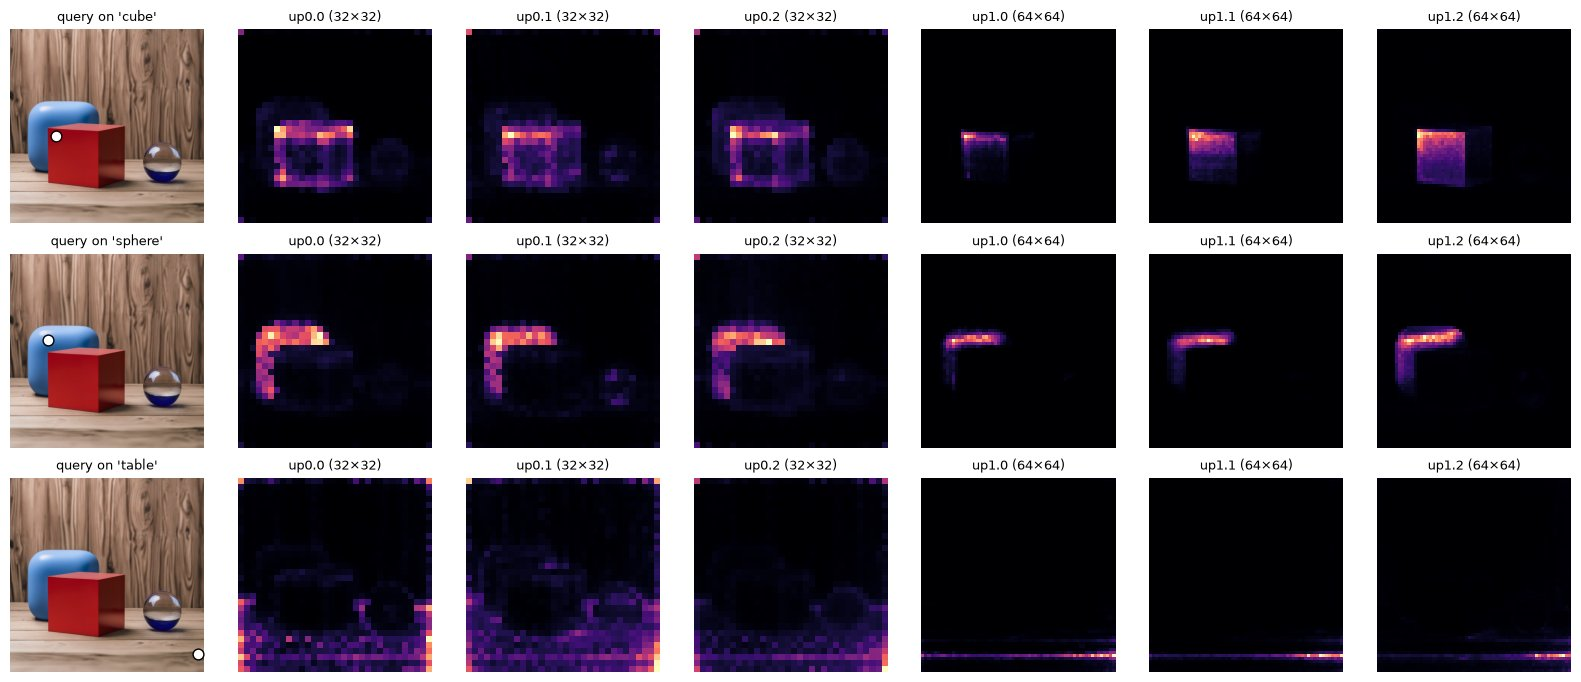

In [52]:
def peak_point(heat):
    """(y, x) of the maximum of a heatmap, as fractions of its height and width in [0, 1)."""
    y, x = divmod(int(heat.argmax()), heat.shape[1])
    return y / heat.shape[0], x / heat.shape[1]


points = {w: peak_point(heatmap(PROMPT, w)) for w in ["cube", "sphere", "table"]}   # one query patch per word
fig, axes = plt.subplots(len(points), len(SELF) + 1, figsize=(2.3 * (len(SELF) + 1), 2.3 * len(points)))
for i, (w, (py, px)) in enumerate(points.items()):
    axes[i, 0].imshow(img); axes[i, 0].scatter([px * img.width], [py * img.height], c="w", s=60, edgecolors="k")
    axes[i, 0].set_title(f"query on '{w}'", fontsize=9); axes[i, 0].axis("off")
    for j, (g, A) in enumerate(SELF.items()):
        side = BLOCK_SIDE[g]
        q = int(py * side) * side + int(px * side)                    # index of the query patch on this grid
        axes[i, j + 1].imshow(to_grid(A[q]).cpu(), cmap="magma"); axes[i, j + 1].axis("off")   # its row of A
        axes[i, j + 1].set_title(f"{short(g)} ({GRID[g]})", fontsize=9)
plt.tight_layout(); plt.show()

**What we see.** A patch attends mostly to the patches of its own object: the patch on the cube lights up the cube,
the patch on the table a strip of the table. The $64 \times 64$ maps are sharp and tight; the $32 \times 32$ maps are
blurrier and also show the outlines of the other objects. The peak of *sphere* lands on the blue rounded box: this is
the object the model drew for *a blue sphere*, next to a small glass ball.

### PCA of self-attention

**The colours themselves mean nothing.** All that matters is that patches of the same colour have similar rows of
$A^{\text{self}}$, i.e. they look at the same places. Don't compare colours between blocks: PCA can flip the sign of a
component or reorder the components, so the same cube is green in one block and purple in another.

How the picture is made:
1. Take the self-attention map: row $i$ holds $N$ numbers, how much patch $i$ attends to every patch.
2. PCA finds the directions in which the rows differ most and gives every patch its coordinates along them.
3. Keep the first 3 coordinates, scale each to [0, 1] and use them as R, G, B.
4. Reshape the $N$ colours back to $H \times W$.

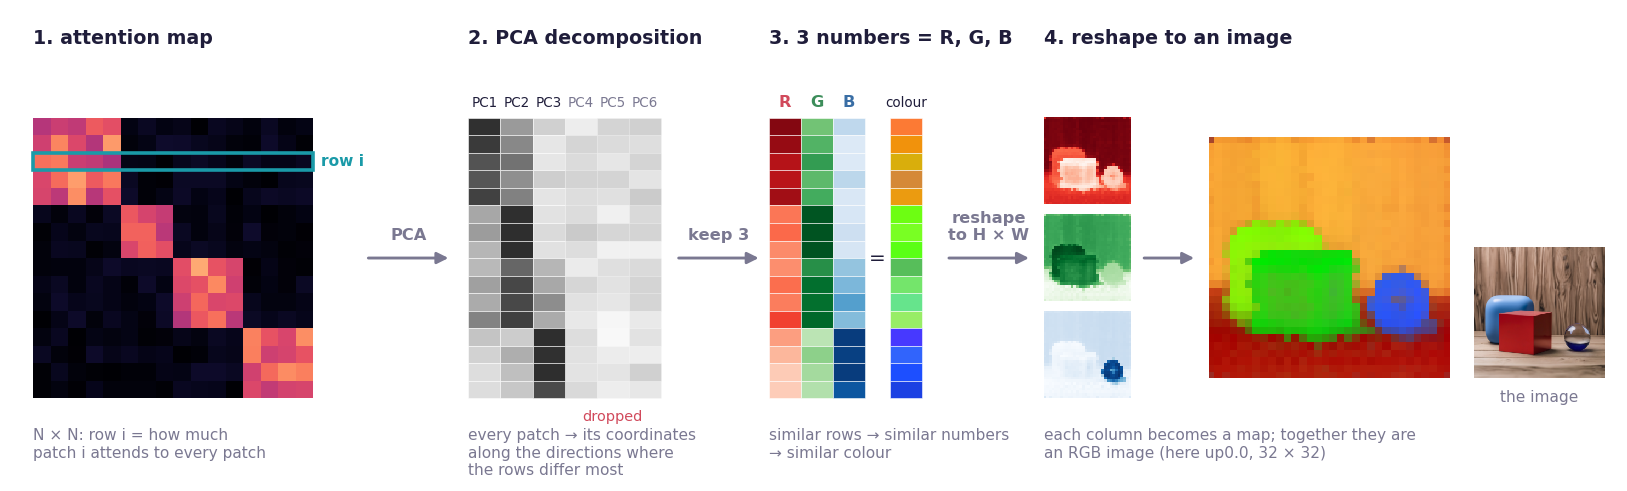

If objects show up as regions of one colour, the rows already encode which object a patch belongs to, without any words.

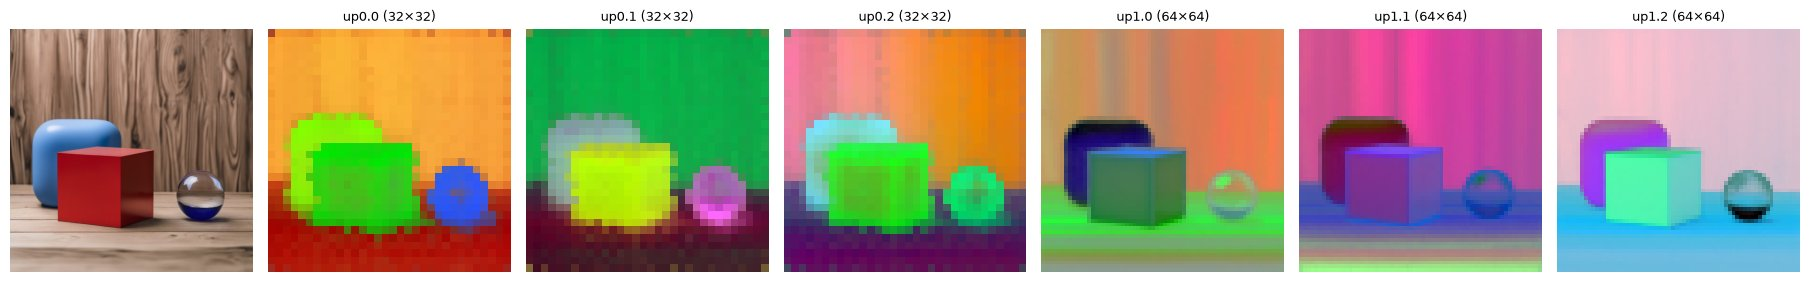

In [54]:
def pca_rgb(A, side, k=3):
    """Top-k principal components of the rows of A ([N, N]), each scaled to [0, 1] -> image [side, side, k]."""
    U, S, V = torch.pca_lowrank(A, q=k, center=True)                    # V: [N, k], the principal directions
    z = (A - A.mean(0)) @ V[:, :k]                                      # [N, k], every patch projected on them
    z = (z - z.min(0).values) / (z.max(0).values - z.min(0).values + 1e-8)   # each component to [0, 1] = a colour
    return z.reshape(side, side, k).cpu().numpy()


fig, axes = plt.subplots(1, len(SELF) + 1, figsize=(2.6 * (len(SELF) + 1), 2.8))
axes[0].imshow(img); axes[0].axis("off")
for ax, (g, A) in zip(axes[1:], SELF.items()):
    ax.imshow(pca_rgb(A, BLOCK_SIDE[g])); ax.set_title(f"{short(g)} ({GRID[g]})", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**What we see.** In every block the cube, the blue box, the glass ball, the table and the wall get different colours, although no word was used. The $32 \times 32$ blocks give coarse regions; the $64 \times 64$ blocks give sharp borders and even show the wood stripes of the wall.

### Segmentation without labels: self-attention clusters

The two kinds of attention complement each other: self-attention locates segments, and cross-attention names them.

1. Cluster the rows of $A^{\text{self}}$ with k-means without using words.
2. Name cluster $k$, containing patches $p$, with the word with the highest mean heatmap inside it:
   $\arg\max_w \operatorname{mean}_{p \in k} \tilde D_w(p)$ (or *background* if all are below 0.3).

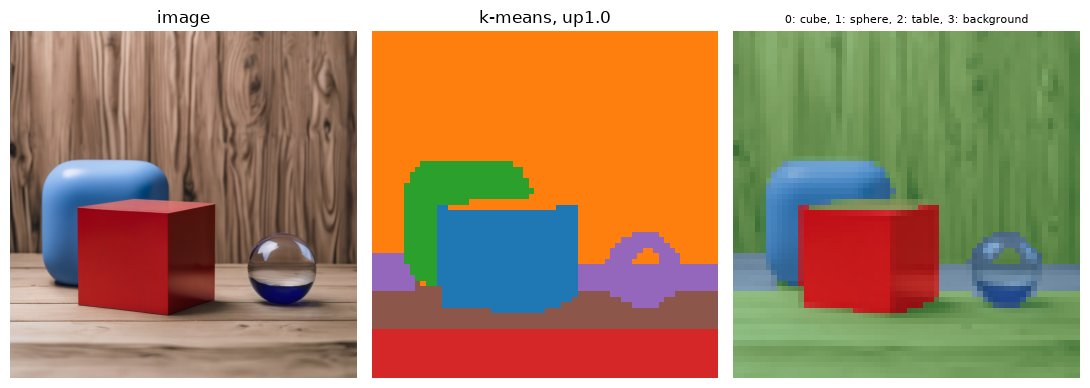

cluster names: ['cube', 'table', 'sphere', 'table', 'sphere', 'table']


In [56]:
from sklearn.cluster import KMeans

SEG_BLOCK = max(SELF, key=lambda g: BLOCK_SIDE[g])        # the first highest-resolution (64×64) up block
K = 6
WORDS = ["cube", "sphere", "table"]

A = SELF[SEG_BLOCK]
side = BLOCK_SIDE[SEG_BLOCK]
U, S, V = torch.pca_lowrank(A, q=min(16, A.shape[0] - 1), center=True)
feats = ((A - A.mean(0)) @ V).cpu().numpy()                 # 16-d PCA features per patch
labels = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(feats).reshape(side, side)

# name the clusters: the word whose (downsampled) heatmap is highest inside the cluster
heats = {w: F.interpolate(normalize(heatmap(PROMPT, w))[None, None], size=(side, side), mode="area")[0, 0].numpy()
         for w in WORDS}
names = []
for c in range(K):
    score = {w: heats[w][labels == c].mean() for w in WORDS}
    best = max(score, key=score.get)
    names.append(best if score[best] > 0.3 else "background")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title("image")
axes[1].imshow(labels, cmap="tab10", vmin=0, vmax=9); axes[1].axis("off"); axes[1].set_title(f"k-means, {short(SEG_BLOCK)}")
named = np.array([(WORDS + ["background"]).index(n) for n in names])[labels]     # cluster id -> name id
axes[2].imshow(img.resize((side, side)))
axes[2].imshow(named, cmap="Set1", alpha=0.55, vmin=0, vmax=8); axes[2].axis("off")
axes[2].set_title(", ".join(f"{i}: {w}" for i, w in enumerate(WORDS + ["background"])), fontsize=8)
plt.tight_layout(); plt.show()
print("cluster names:", names)

**What we see.** Self-attention alone separates the cube, the blue box, the glass ball, the table top and the wall.

Cross-attention then names the segments, mostly correctly: the cube is *cube*, the ball and the blue box are both *sphere*. The wall is called *table*: no word of the prompt describes it, and the map of *table* spreads over it.

### Tasks §3

**3.1. Which steps reveal structure?** Rerun §3 with `SELF_STEPS = set(range(0, STEPS // 3))` (early) and
`set(range(2 * STEPS // 3, STEPS))` (late) and plot the k-means segmentation for each window. Which time window gives the
cleanest clusters?

In [58]:
# Task 3.1: your code

**3.2. Cross vs self for segmentation.** Cluster the *cross*-attention instead: for every patch use its
77-dimensional row of `CROSS[(block, step)]` summed over steps. Plot both segmentations. Which is sharper, and why?

In [60]:
# Task 3.2: your code

## 4. Editing an image through its attention maps (Prompt-to-Prompt)

Cross-attention decides where words go, and self-attention represents structure. Giving a new prompt
an earlier generation’s maps should change the content while keeping the layout
([Prompt-to-Prompt](https://arxiv.org/abs/2208.01626)).

We run the source prompt $\mathcal P$ and the target prompt $\mathcal P^*$ in one batch from the same noise. Of $T$ steps, the target uses edited maps $\hat M_t$ for the fraction $\tau_c$.

The method in the figure of the Prompt-to-Prompt paper. Top: one cross-attention layer. Bottom: the three ways to edit
its maps.

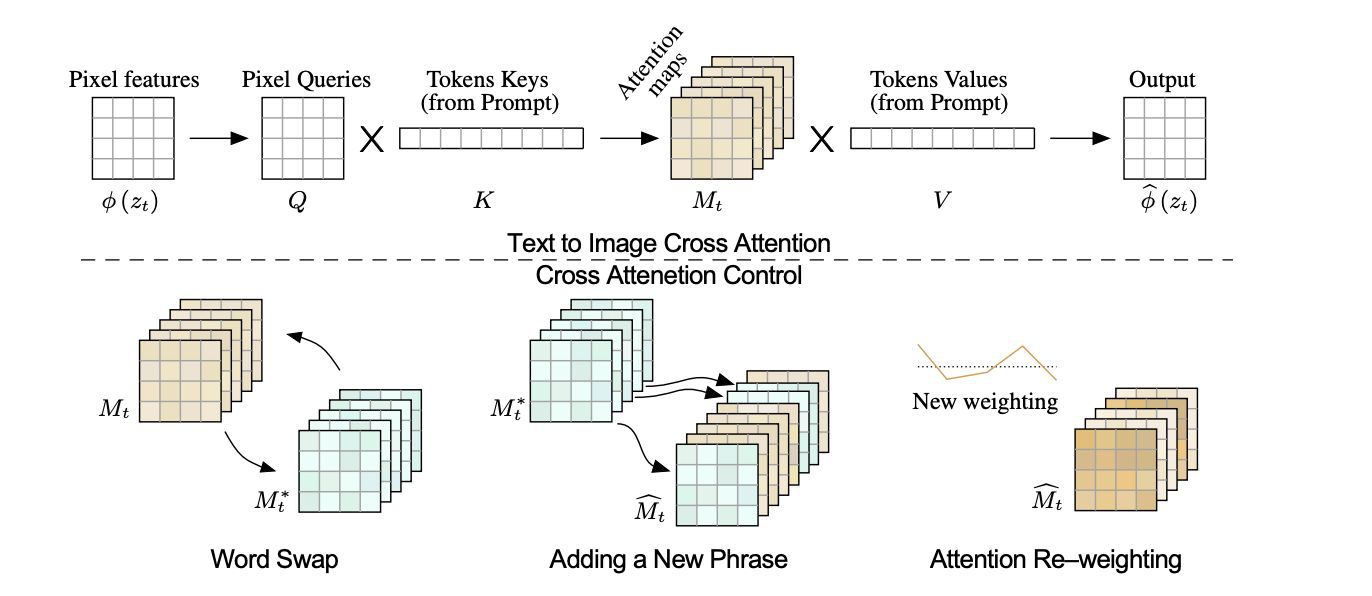

At step $t$, counted from noise:

$$\hat M_t = \begin{cases} \mathrm{Edit}(M_t, M^*_t) & t < \tau_c T, \\ M^*_t & \text{otherwise}, \end{cases}$$

Here $M_t$ and $M^*_t$ are source and target maps.

* **word swap** (*cube → cake*): $\mathrm{Edit} = M_t$, the new word takes the old word's map.
* **refinement** (words added): $\big(\hat M_t\big)_{:,j} = (M_t)_{:,a(j)}$ if target token $j$ is aligned to source
  token $a(j)$, otherwise $(M^*_t)_{:,j}$.
* **re-weighting** ($\mathcal P^* = \mathcal P$): $\big(\hat M_t\big)_{:,j^\star} = c\,(M_t)_{:,j^\star}$ scales word
  $j^\star$ by $c$.

The target copies source **self-attention** for $t < \tau_s T$, the fraction $\tau_s$ of steps.
As in the paper, we copy only in low-resolution ($32 \times 32$) blocks: a $64 \times 64$ self-attention map has $4096 \times 4096$ entries per head.

In [64]:
LOW_RES = [b for b in BLOCKS if BLOCK_SIDE[b] <= 32]    # self-attention is injected only in these blocks


def p2p_mapper(src, tgt):
    """For each of the 77 text positions of `tgt`: the aligned position in `src`, or -1 for a new token.

    Equal tokens and same-length replacements (word swaps) are aligned; inserted tokens (refinement) get -1.
    """
    a = tok(src, padding="max_length", max_length=CTX_LEN, truncation=True).input_ids
    b = tok(tgt, padding="max_length", max_length=CTX_LEN, truncation=True).input_ids
    m = torch.full((CTX_LEN,), -1, dtype=torch.long)
    for op, i1, i2, j1, j2 in SequenceMatcher(None, a, b, autojunk=False).get_opcodes():   # difflib: align a to b
        if op == "equal" or (op == "replace" and i2 - i1 == j2 - j1):
            m[j1:j2] = torch.arange(i1, i2)
    return m


def p2p(src, tgt, cross=0.8, self_=0.4, weights=None, seed=SEED, steps=STEPS):
    """Prompt-to-Prompt: generate `src` and `tgt` from the same noise; the target gets the source's attention maps.

    Args:
        cross: tau_c, fraction of the steps with cross-attention injection (0 = plain generation of `tgt`)
        self_: tau_s, fraction of the steps with self-attention injection
        weights: {word or text position: c}, re-weighting of target tokens
    Returns: (source image, edited target image)
    """
    mapper = p2p_mapper(src, tgt).to(DEVICE)
    keep = mapper >= 0                                                  # target tokens that have a source token
    n_cross, n_self = round(cross * steps), round(self_ * steps)        # number of steps with injection
    weights = {j: c for w, c in (weights or {}).items()                 # words -> their text positions
               for j in ([w] if isinstance(w, int) else word_positions(tgt, w))}

    def edit(A, info):                       # the last two batch rows are the prompt branch of [source, target]
        if info["cross"] and info["step"] < n_cross:
            A = A.clone()
            A[-1, ..., keep] = A[-2, ..., mapper[keep]]       # target columns <- aligned source columns
            for j, c in weights.items():
                A[-1, ..., j] *= c                            # re-weighting
        elif not info["cross"] and info["step"] < n_self:
            A = A.clone()
            A[-1] = A[-2]                                     # target self-attention <- source self-attention
        return A

    noise = torch.randn(1, 4, RES // 8, RES // 8, generator=torch.Generator("cpu").manual_seed(seed))   # SDXL latent
    noise = noise.repeat(2, 1, 1, 1)                                                     # same noise for both prompts
    images = generate([src, tgt], steps=steps, latents=noise.to(DEVICE, DTYPE), edits=[edit],
                      self_blocks=LOW_RES if self_ > 0 else (), record=False)
    return tuple(images)

### Word swap

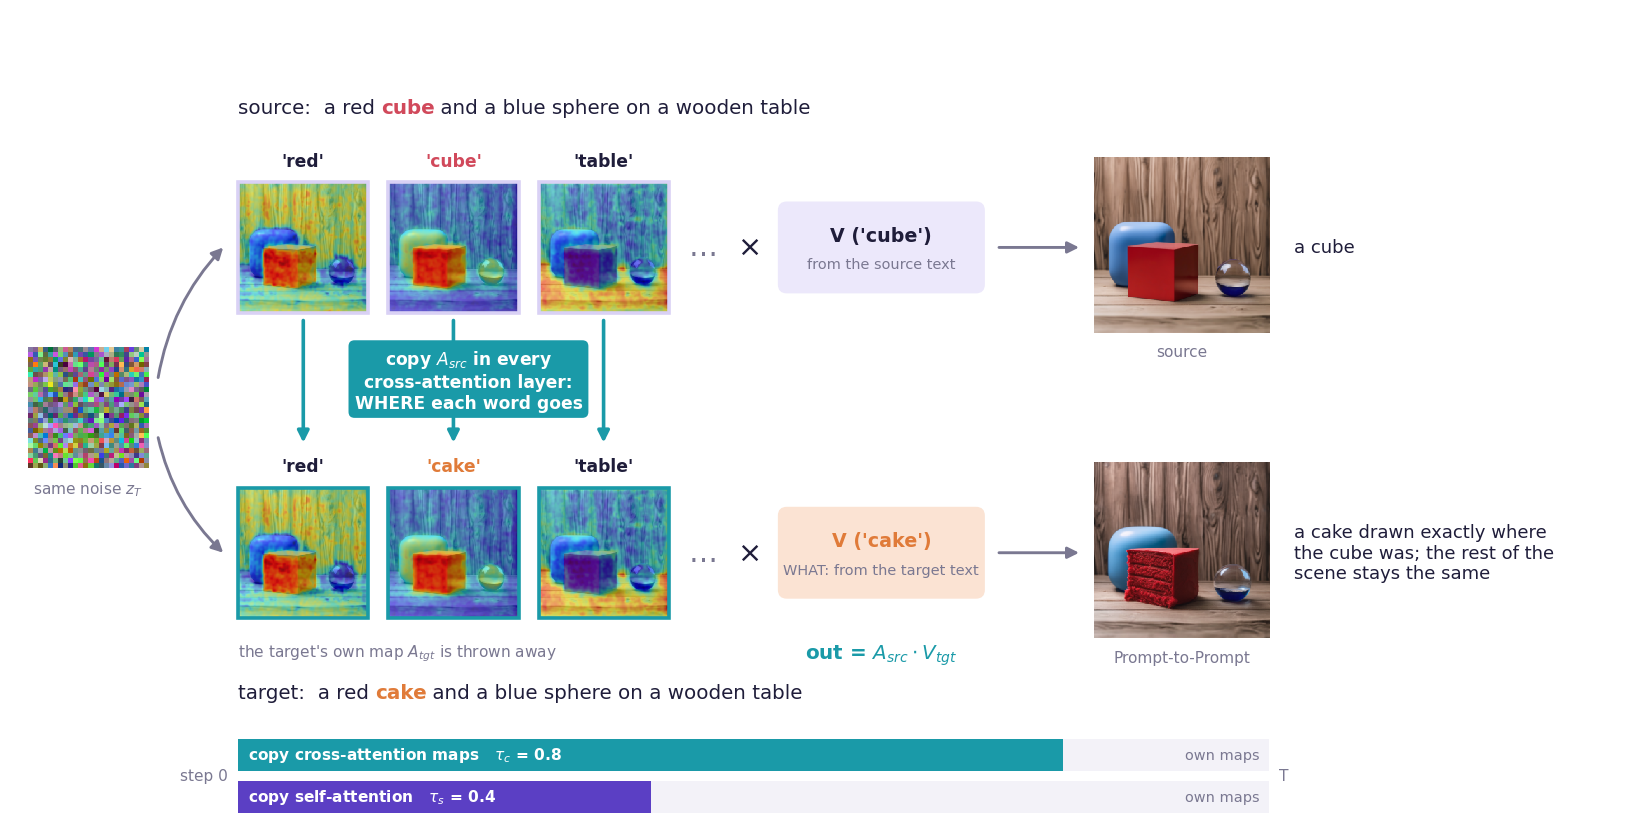

In a cross-attention layer the map $A$ decides **where** each word is drawn, and the values $V$ decide **what** is drawn
there. For the first $\tau_c$ of the steps the target takes the map of the source and keeps its own values:
$\text{out} = A_{src} V_{tgt}$. So *cake* is drawn exactly where *cube* was. For the first $\tau_s$ of the steps the
target also copies the source self-attention (in the $32 \times 32$ blocks), which keeps the shapes of the objects.

For each edit, we show the source, the unedited target ($\tau_c = \tau_s = 0$) and P2P, all from the same noise.

cube → cake | 

red → green | 

wooden → glass | 

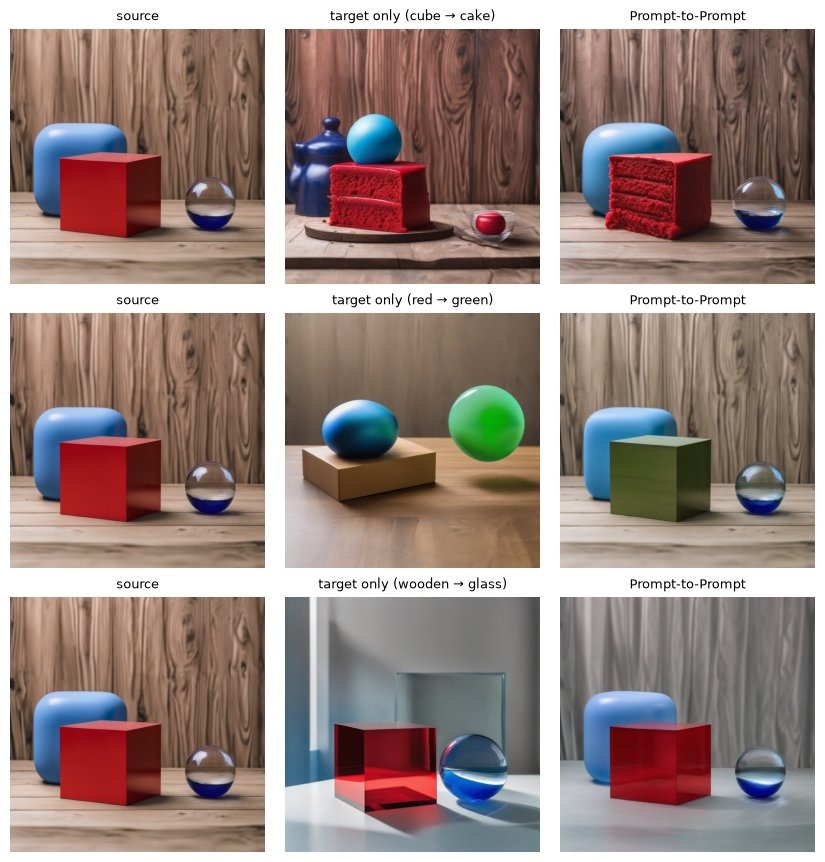

In [66]:
SWAPS = [("cube", "cake"), ("red", "green"), ("wooden", "glass")]
rows_p2p = []
for a, b in SWAPS:                                       # for every swap: source, plain target, edited target
    print(f"{a} → {b}", end=" | ", flush=True)
    tgt = PROMPT.replace(a, b)
    src_img, plain = p2p(PROMPT, tgt, cross=0, self_=0)
    _, edited = p2p(PROMPT, tgt)
    rows_p2p.append((f"{a} → {b}", src_img, plain, edited))

fig, axes = plt.subplots(len(rows_p2p), 3, figsize=(8.4, 2.9 * len(rows_p2p)))
for i, (name, s, pl, ed) in enumerate(rows_p2p):
    for ax, im, t in zip(axes[i], [s, pl, ed], ["source", f"target only ({name})", "Prompt-to-Prompt"]):
        ax.imshow(im); ax.set_title(t, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

### How long must the maps be injected?

This swap needs a **different shape**: *cube → pyramid*. Vary $\tau_c$ with no self-attention injection and compare with the step where the layout is fixed.

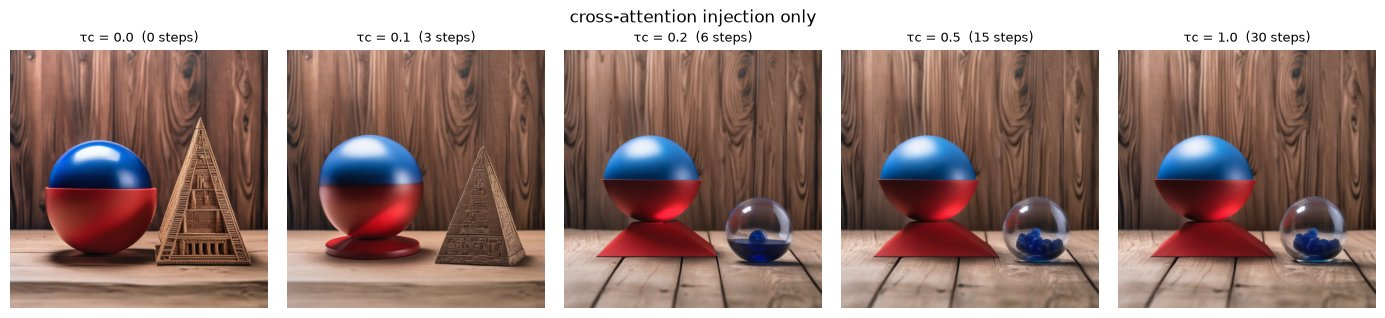

In [68]:
TGT = PROMPT.replace("cube", "pyramid")
taus = [0.0, 0.1, 0.2, 0.5, 1.0]
ims = [p2p(PROMPT, TGT, cross=tc, self_=0)[1] for tc in taus]         # [1] = the edited target
show_row(ims, [f"τc = {tc}  ({round(tc * STEPS)} steps)" for tc in taus], suptitle="cross-attention injection only")

### Self-attention alone

We repeat the swap, copying only self-attention ($\tau_c = 0$). Does the shape come from self-attention?

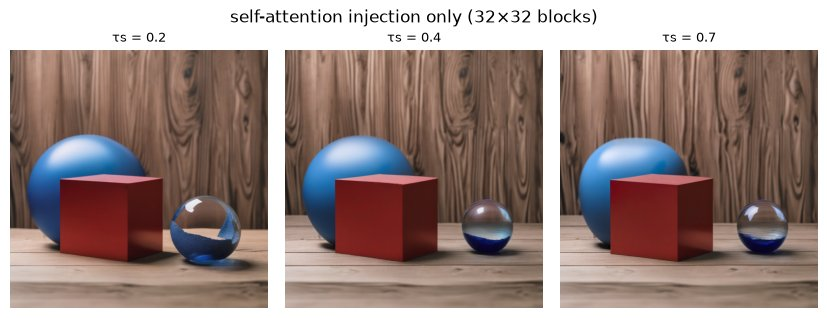

In [70]:
taus = [0.2, 0.4, 0.7]
ims = [p2p(PROMPT, TGT, cross=0, self_=ts)[1] for ts in taus]
show_row(ims, [f"τs = {ts}" for ts in taus], suptitle="self-attention injection only (32×32 blocks)")

### Refinement and re-weighting

* **Refinement** (adding words). The target prompt is the source prompt plus new words, here *watercolor painting*.
  `p2p_mapper` aligns the tokens that both prompts share, and for them the target uses the source's maps, so every
  object stays where it was. The new tokens have no partner in the source, so they keep their own maps and can act on
  the whole image: the scene stays, the style changes.
* **Re-weighting** (one word stronger or weaker). The prompt stays the same. We only multiply the column of one word in
  the cross-attention maps by $c$: with $c > 1$ every patch reads more of this word, with $c < 1$ less, and $c = 0$
  removes it from the maps. Below we scale *red*.

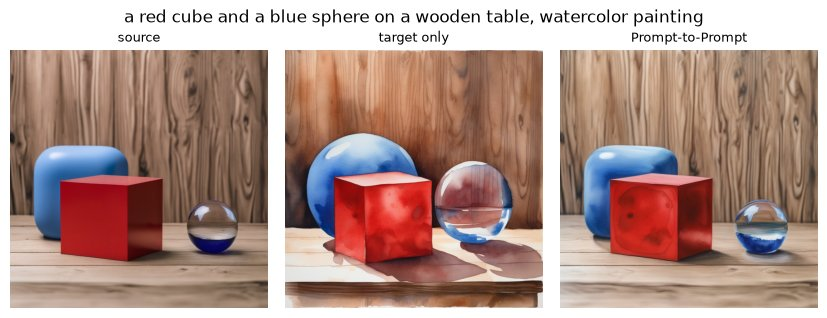

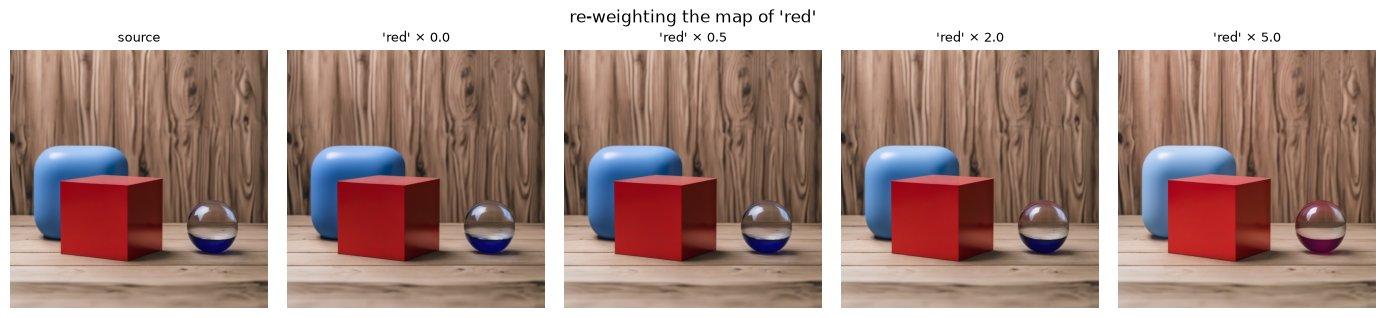

In [72]:
REFINE = PROMPT + ", watercolor painting"
src_img, plain = p2p(PROMPT, REFINE, cross=0, self_=0)
_, edited = p2p(PROMPT, REFINE, cross=0.8, self_=0.4)
show_row([src_img, plain, edited], ["source", "target only", "Prompt-to-Prompt"], suptitle=REFINE)

cs = [0.0, 0.5, 2.0, 5.0]
ims = [p2p(PROMPT, PROMPT, cross=0.8, self_=0.4, weights={"red": c})[1] for c in cs]
show_row([src_img] + ims, ["source"] + [f"'red' × {c}" for c in cs], suptitle="re-weighting the map of 'red'")

### Tasks §4

**4.1. Minimal injection.** For *cube → cake* (with `self_=0`), find the smallest `cross` that keeps the position and
size of the object. Convert it to steps and compare with the step where the IoU curve of *When is the layout fixed?* levels off. Do they agree?

In [74]:
# Task 4.1: your code

**4.2. Re-weighting vs removing.** Even `'red' × 0` keeps the cube red. Re-weight `red` together with `<eos>` and the padding positions. Does the cube
lose its colour now?

In [76]:
# Task 4.2: your code

## 5. Where does the attention mass go, and is it needed?

The text always has 77 positions: `<sot>`, the words, `<eos>`, padding. In LLMs and ViTs a few
tokens receive most of the attention without providing content (*attention sinks*,
[Xiao et al.](https://arxiv.org/abs/2309.17453), [Darcet et al.](https://arxiv.org/abs/2309.16588)). Is this true for SDXL, and which tokens provide the prompt information?

Our prompt as 77 text positions (the colours are the same as in the plots below):

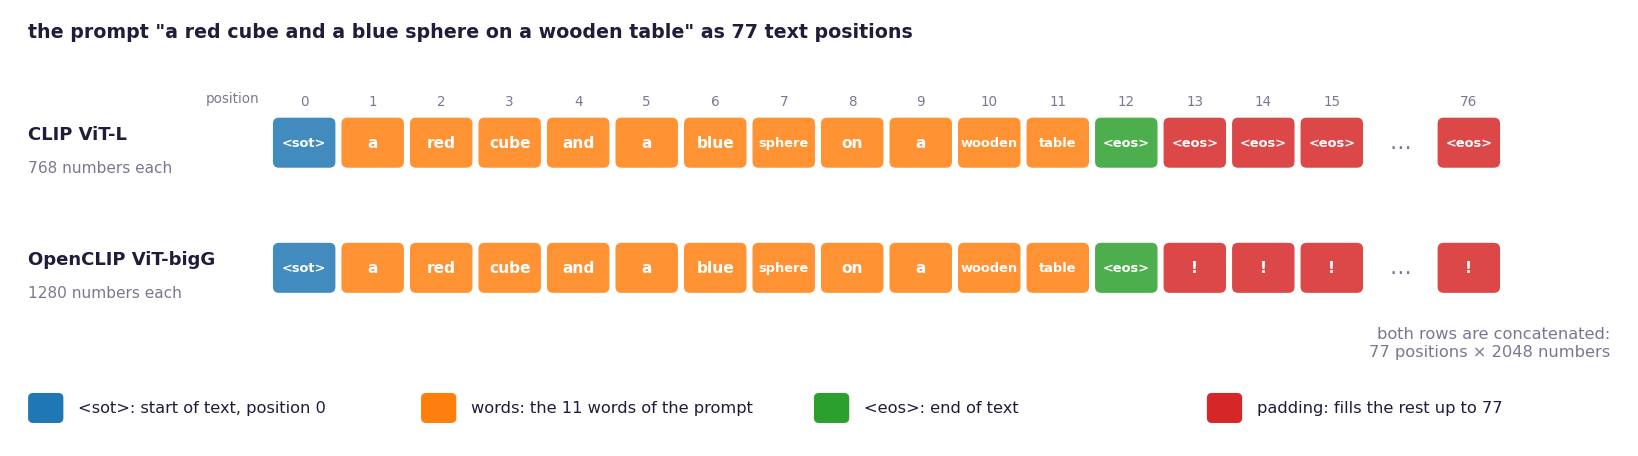

We sum attention over positions $\mathcal T$ of each token type and average over $N$ image patches $i$:

$$m_{\mathcal T} = \frac1N \sum_{i=1}^{N} \sum_{j \in \mathcal T} A_{ij},$$

We **drop** positions $\mathcal D$ of one type and renormalize over the rest, using attention scores $s_{ij}$: $A_{ij} = \exp(s_{ij}) \,/\, \sum_{k \notin \mathcal D} \exp(s_{ik})$ for $j \notin \mathcal D$.

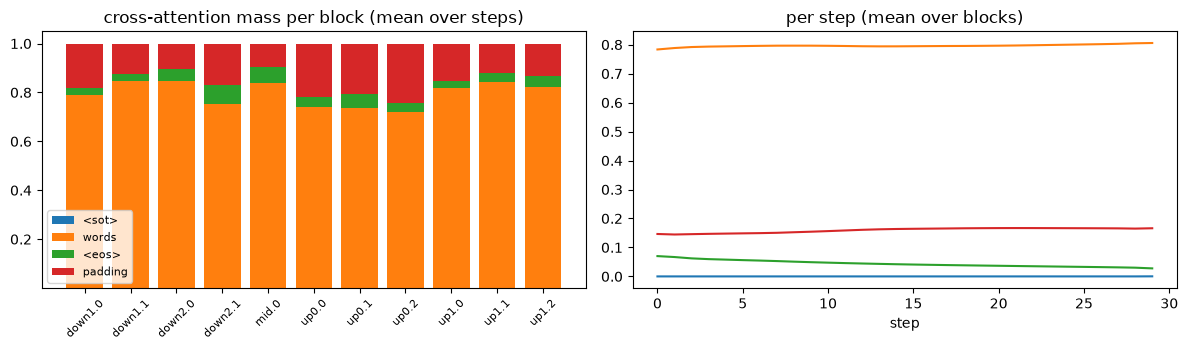

In [80]:
def token_types(prompt):
    """Text positions of each token type: {"<sot>": [0], "words": [...], "<eos>": [e], "padding": [e+1, ..., 76]}."""
    eos = len(tok(prompt).input_ids) - 1                 # position of <eos> = number of tokens - 1
    return {"<sot>": [0], "words": list(range(1, eos)), "<eos>": [eos], "padding": list(range(eos + 1, CTX_LEN))}


img = generate(PROMPT)
types = token_types(PROMPT)
run_steps = sorted({s for _, s in CROSS})
# mass[t][i, j] = m_T of token type t in block i at step j (each map averaged over the image patches)
mass = {t: np.array([[float(CROSS[(b, s)].mean(0)[idx].sum()) for s in run_steps] for b in BLOCKS])
        for t, idx in types.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
bottom = np.zeros(len(BLOCKS))
for t in types:
    vals = mass[t].mean(1)                                # per block, mean over steps
    axes[0].bar([short(g) for g in BLOCKS], vals, bottom=bottom, label=t); bottom += vals
axes[0].set_title("cross-attention mass per block (mean over steps)"); axes[0].legend(fontsize=8)
axes[0].tick_params(axis="x", labelsize=8, rotation=45)
for t in types:
    axes[1].plot(run_steps, mass[t].mean(0), label=t)    # per step, mean over blocks
axes[1].set_title("per step (mean over blocks)"); axes[1].set_xlabel("step")
plt.tight_layout(); plt.show()

### Remove the sink, remove the padding, remove the words

We keep the seed fixed and drop token types from conditional cross-attention. The last image uses **only** special
tokens. Do `<eos>` and padding still provide the prompt information?

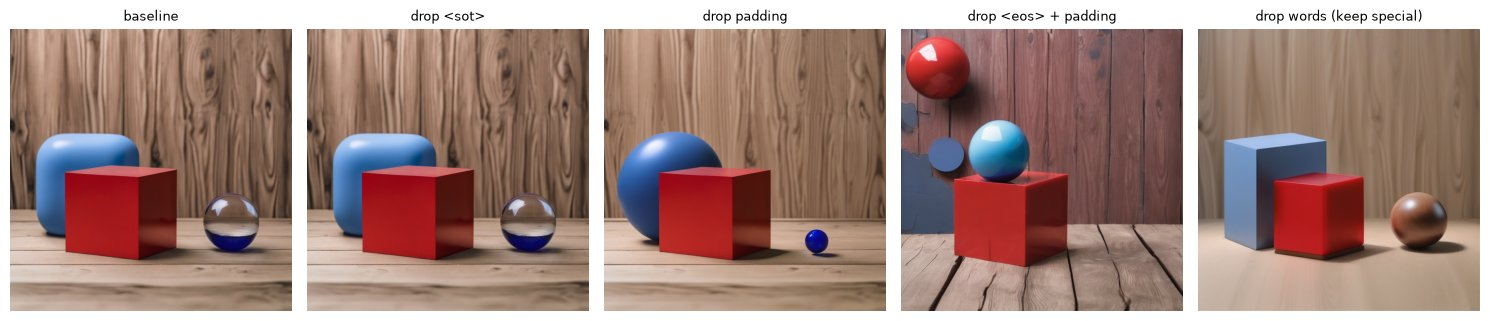

In [82]:
def drop_tokens(positions, branch="cond"):
    """Attention edit: remove the text `positions` from cross-attention and renormalize each row over the rest.

    This is the same as removing them before the softmax. branch: "cond" = only the prompt branch of CFG,
    "both" = also the unconditional branch.
    """
    def edit(A, info):
        if not info["cross"]:
            return A
        rows = info["cond"] if branch == "cond" else slice(None)   # which CFG branches to edit
        A = A.clone()
        A[rows, ..., positions] = 0                                # nobody reads these tokens
        A[rows] = A[rows] / A[rows].sum(-1, keepdim=True)          # every row sums to 1 again
        return A

    return edit


t = token_types(PROMPT)
conditions = {
    "baseline": None,
    "drop <sot>": t["<sot>"],
    "drop padding": t["padding"],
    "drop <eos> + padding": t["<eos>"] + t["padding"],
    "drop words (keep special)": t["words"],
}
show_row([generate(PROMPT, edits=[drop_tokens(d)] if d else []) for d in conditions.values()],   # same seed
         list(conditions), size=3)

### Tasks §5

**5.1. Which tokens preserve the prompt?** Keep only `<eos>` (drop words + padding) and only padding (drop words + `<eos>`). Which of them still produces a red cube and a blue sphere? What does this mean for edits that change only the word tokens, like the word swap of §4?

In [86]:
# Task 5.1: your code

## 6. Where is the colour decided? (activation patching)

Maps show where patches attend to a word, but not where the model makes a decision. Which blocks and steps cause the cube to be red? ([Basu et al. 2023](https://arxiv.org/abs/2310.13730),
[Basu et al. 2024](https://arxiv.org/abs/2405.01008))

We compare three runs with the same seed:

* **clean**: *"a **red** cube on a wooden table"*. We record every block output $h^{(\ell,t)}_\text{clean}$;
* **corrupted**: *"a **blue** cube on a wooden table"*;
* **patched**: the corrupted run with $h^{(\ell,t)} \leftarrow h^{(\ell,t)}_\text{clean}$ for chosen blocks $\ell$ and steps $t$.

Score $s$ is the red pixel share minus the blue pixel share inside the cube mask. Restoration $R$ is:

$$R = \frac{s_\text{patched} - s_\text{corrupted}}{s_\text{clean} - s_\text{corrupted}} \qquad (R = 1: \text{fully red again},\ R = 0: \text{no effect}).$$

We use 20 steps to keep the sweep short.

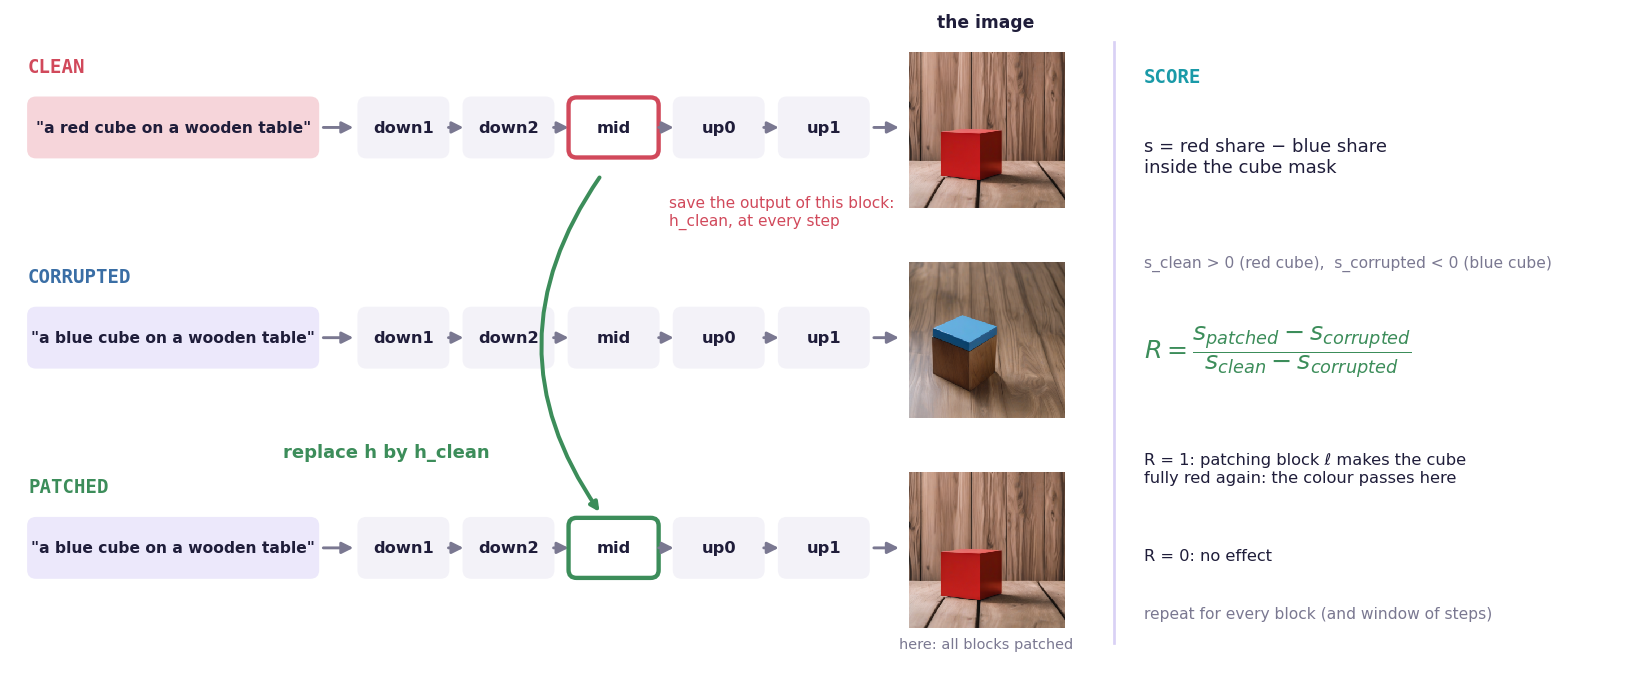

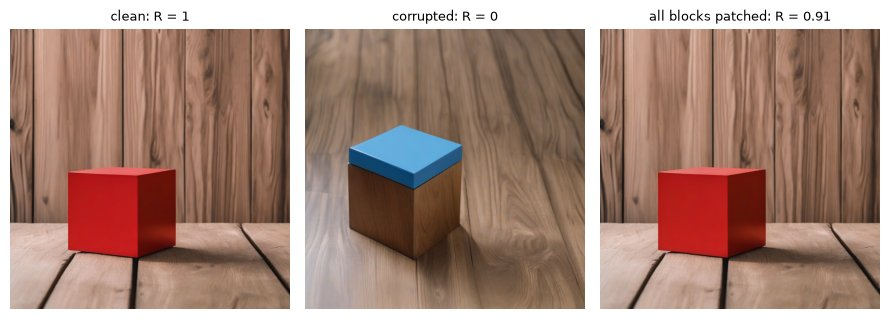

In [92]:
CLEAN = "a red cube on a wooden table"
CORRUPT = "a blue cube on a wooden table"
PSTEPS = 20


def color_share(img, mask, color):
    """Pixel leak: share of `mask` covered by vivid pixels of `color` ("red", "blue" or "green")."""
    hsv = np.asarray(img.resize(mask.shape[::-1]).convert("HSV")) / 255    # image at the mask's size, values in [0, 1]
    hue, vivid = hsv[..., 0], (hsv[..., 1] > 0.35) & (hsv[..., 2] > 0.2)    # saturated and not too dark
    band = {"red": (hue < 0.05) | (hue > 0.93), "blue": (hue > 0.55) & (hue < 0.72), "green": (hue > 0.22) & (hue < 0.45)}
    m = mask.numpy()
    return float((m & vivid & band[color]).sum() / m.sum())



def cube_score(im, prompt):
    """s = red share - blue share inside the cube mask of the run that has just finished (its maps are in CROSS)."""
    m = binarize(heatmap(prompt, "cube"))
    return color_share(im, m, "red") - color_share(im, m, "blue")


CLEAN_OUT = {}   # (block, step) -> output of the block in the clean run (on CPU)


def save_output(block):
    """Block hook: store the block's output at every step in CLEAN_OUT."""
    def hook(h, step):
        CLEAN_OUT[(block, step)] = h.cpu()
    return hook


def patch_output(block, steps=None):
    """Block hook: replace the block's output by the clean one at `steps` (None = all steps)."""
    def hook(h, step):
        if steps is None or step in steps:
            return CLEAN_OUT[(block, step)].to(h.device)
    return hook


CLEAN_OUT.clear()
img_clean = generate(CLEAN, steps=PSTEPS, block_hooks={b: save_output(b) for b in BLOCKS})   # clean run, outputs saved
S_CLEAN = cube_score(img_clean, CLEAN)
img_corrupt = generate(CORRUPT, steps=PSTEPS)
S_CORRUPT = cube_score(img_corrupt, CORRUPT)


def run_scored(prompt=CORRUPT, **gen_kwargs):
    """Run the corrupted prompt (with the given `generate` arguments) -> (image, restoration R)."""
    im = generate(prompt, steps=PSTEPS, **gen_kwargs)
    return im, (cube_score(im, CORRUPT) - S_CORRUPT) / (S_CLEAN - S_CORRUPT + 1e-8)   # R: 0 = corrupted, 1 = clean


def patched_run(blocks, steps=None):
    """Corrupted run with the outputs of `blocks` at `steps` (None = all) replaced by the clean ones -> (image, R)."""
    return run_scored(block_hooks={b: patch_output(b, steps) for b in blocks})


im_all, r_all = patched_run(BLOCKS)
show_row([img_clean, img_corrupt, im_all], ["clean: R = 1", "corrupted: R = 0", f"all blocks patched: R = {r_all:.2f}"], size=3)

### One block at a time

down1.0 

down1.1 

down2.0 

down2.1 

mid.0 

up0.0 

up0.1 

up0.2 

up1.0 

up1.1 

up1.2 

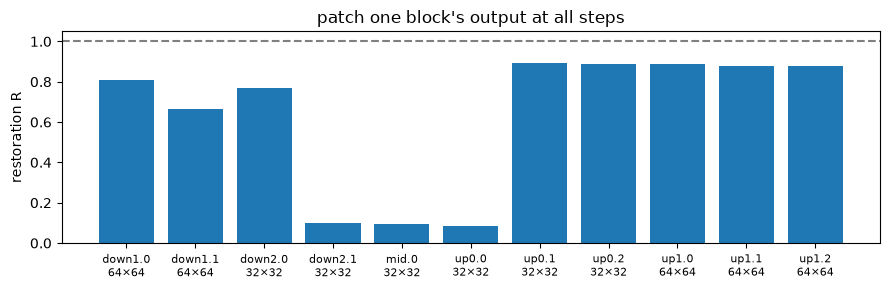

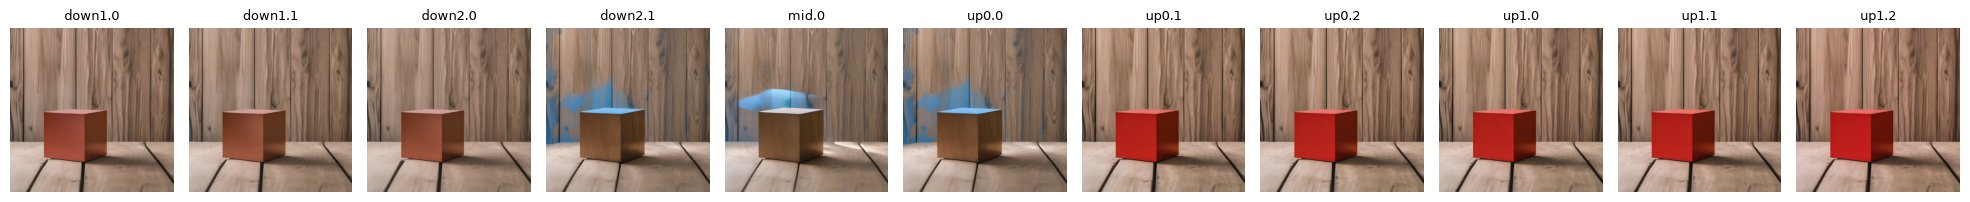

In [94]:
patched = {}                                             # block -> (image, R)
for g in BLOCKS:
    print(short(g), end=" ", flush=True)
    patched[g] = patched_run([g])
rest = [patched[g][1] for g in BLOCKS]

plt.figure(figsize=(9, 3))
plt.bar([f"{short(g)}\n{GRID[g]}" for g in BLOCKS], rest)
plt.axhline(1, ls="--", c="gray"); plt.axhline(0, c="k", lw=0.5)
plt.ylabel("restoration R"); plt.title("patch one block's output at all steps")
plt.xticks(fontsize=8); plt.tight_layout(); plt.show()
show_row([patched[g][0] for g in BLOCKS], [short(g) for g in BLOCKS], size=1.8)

### When is the colour decided?

Patch **all blocks**, but only inside a window of steps.

steps 0–1 | 

steps 0–4 | 

steps 5–9 | 

steps 10–19 | 

steps 0–9 | 

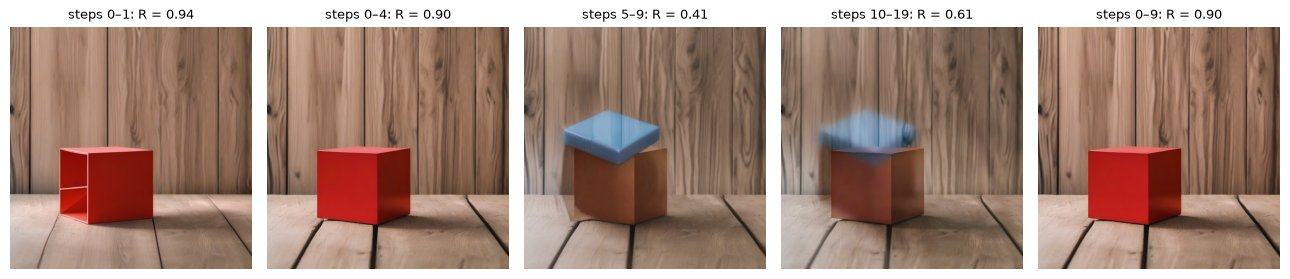

In [96]:
q = PSTEPS // 4
windows = [range(0, 2), range(0, q), range(q, 2 * q), range(2 * q, PSTEPS), range(0, PSTEPS // 2)]
ims, titles = [], []
for steps in windows:
    print(f"steps {steps.start}–{steps.stop - 1}", end=" | ", flush=True)
    im, r = patched_run(BLOCKS, steps=set(steps))                     # all blocks, only these steps
    ims.append(im); titles.append(f"steps {steps.start}–{steps.stop - 1}: R = {r:.2f}")
show_row(ims, titles, size=2.6)

### Which blocks *use* the colour word?

We keep corrupted image states and give one block **clean text** embeddings $c_\text{clean}$ (*red*):
$K = W_K\,c_\text{clean}$, $V = W_V\,c_\text{clean}$ in that block only, using key/value projections $W_K$ and $W_V$.
If this makes the cube red, that block uses the word.

SDXL also adds a **pooled text embedding** into the time embedding, a second route for the text that bypasses
cross-attention. The last run swaps only that route.

down1.0 

down1.1 

down2.0 

down2.1 

mid.0 

up0.0 

up0.1 

up0.2 

up1.0 

up1.1 

up1.2 

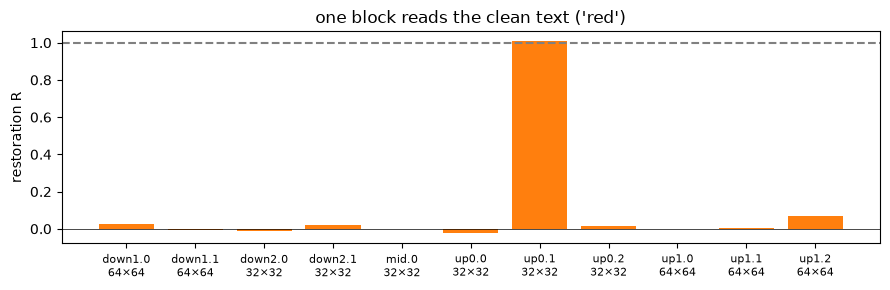

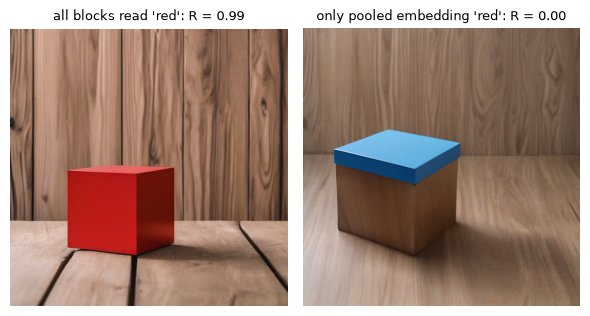

In [98]:
pe_clean, npe, pool_clean, npool = pipe.encode_prompt(CLEAN, device=DEVICE)    # prompt, negative, pooled, negative pooled
pe_corr, _, _, _ = pipe.encode_prompt(CORRUPT, device=DEVICE)
ctx_clean = torch.cat([npe, pe_clean])          # the CFG batch is [uncond, cond]


def text_patched_run(blocks, steps=None):
    """Corrupted run where the cross-attention of `blocks` reads the clean text at `steps` (None = all) -> (image, R)."""
    def read_clean(c, step):                 # text hook: the clean text at the chosen steps, else the own text
        return ctx_clean if steps is None or step in steps else c
    return run_scored(text_hooks={b: read_clean for b in blocks})


text_rest = []                                           # R when only block g reads 'red'
for g in BLOCKS:
    print(short(g), end=" ", flush=True)
    text_rest.append(text_patched_run([g])[1])
im_txt, r_txt = text_patched_run(BLOCKS)
im_pool, r_pool = run_scored(prompt=None, prompt_embeds=pe_corr, pooled_prompt_embeds=pool_clean,   # only the
                             negative_prompt_embeds=npe, negative_pooled_prompt_embeds=npool)       # pooled text is clean

plt.figure(figsize=(9, 3))
plt.bar([f"{short(g)}\n{GRID[g]}" for g in BLOCKS], text_rest, color="tab:orange")
plt.axhline(1, ls="--", c="gray"); plt.axhline(0, c="k", lw=0.5)
plt.ylabel("restoration R"); plt.title("one block reads the clean text ('red')"); plt.xticks(fontsize=8)
plt.tight_layout(); plt.show()
show_row([im_txt, im_pool], [f"all blocks read 'red': R = {r_txt:.2f}", f"only pooled embedding 'red': R = {r_pool:.2f}"], size=3)

### Tasks §6

**6.1. One block, few steps.** Combine the two last experiments: give clean text only to the block found in *Which blocks use the colour word?*, and only at steps 0–1 (`text_patched_run([block], steps={0, 1})`). Compare $R$ with patching at all steps.

In [ ]:
# Task 6.1: your code

**6.2. Another attribute.** Repeat *Which blocks use the colour word?* with `"red"` → `"green"` (change `CLEAN` and the score to green − blue).
Is it the same block? Does that block also use the object word (*cube → sphere*)? Compare with
[InstantStyle](https://arxiv.org/abs/2404.02733) and [B-LoRA](https://arxiv.org/abs/2403.14572), which found that a single SDXL block (`up_blocks.0.attentions.1`) controls style and content.

In [ ]:
# Task 6.2: your code

## 7. Research task (choose one)

Choose **one** of the two questions. Write it up like a short paper: a hypothesis, the smallest experiment that tests
it, one figure, and a conclusion in 3–5 sentences.

### Option A · Style from a reference image

Can SDXL draw a new image in the style of a reference image, without any training? One way is to share self-attention
between the two generations: the patches of the new image also attend to the keys and values of the reference image.

Papers: [StyleAligned](https://arxiv.org/abs/2312.02133), [StyleID](https://arxiv.org/abs/2312.09008).

**Task.** Implement style sharing on top of the attention processor of this notebook. Which self-attention layers carry
the style, and which carry the content? Does content of the reference leak into the new image?

### Option B · Depth from diffusion features

SDXL never sees depth during training, yet to draw a scene it has to know what is near and what is far. Is depth
written in its features?

Papers: [Beyond Surface Statistics](https://arxiv.org/abs/2306.05720), [VPD](https://arxiv.org/abs/2303.02153),
[Depth Anything V2](https://arxiv.org/abs/2406.09414) (for pseudo ground truth).

**Task.** Train a small depth estimator on the outputs of U-Net blocks. Which block and which denoising step give the
best depth? Is depth there before the image itself becomes visible?

In [ ]:
# Task 7 (option A): your code

In [ ]:
# Task 7 (option B): your code